8:00 - 9:30
15 min przerwy
9:45 - 11:15
30 minut przerwy
11:45 - 14:00

# Rachunek prawdopodobieństwa i wnioskowanie statystyczne

**Przypomnienie** — na poprzednich zajęciach omówiliście:
- Skale pomiarowe (nominalna, porządkowa, przedziałowa, ilorazowa)
- Miary średnie i położenia (średnia, mediana, dominanta, kwartyle)
- Miary zmienności (wariancja, odchylenie standardowe, rozstęp, współczynnik zmienności)
- Miary skośności (asymetrii)
- Miary koncentracji (kurtoza)
- Podstawy matematyki: funkcje wykładnicze, logarytmiczne, logistyczne, sigmoid, zapis z użyciem $\Sigma$

Dzisiaj przejdziemy od **opisywania danych** (statystyka opisowa) do **wyciągania wniosków** (statystyka matematyczna / wnioskowanie statystyczne). 

Statystyka matematyczna opiera się na rachunku prawdopodobieństwa. Na podstawie ograniczonych danych formułujemy hipotezy, a następnie wyciągamy wnioski oraz obliczamy związaną z nimi niepewność.

Polecane ksiązki do statystyki:
 - Mieczysław Sobczyk, Statystyka (mozna znaleźć w większości bibliotek), https://lubimyczytac.pl/ksiazka/131593/statystyka
 - An Introduction to Statistics with Python, https://link.springer.com/book/10.1007/978-3-030-97371-1

In [1]:
# Importowanie bibliotek
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from scipy import stats

# Ustawienie ziarna losowości — dzięki temu wyniki będą powtarzalne
np.random.seed(42)

In [8]:
x = [4,7,10,15,8]

np.mean(x) # 8.8
# 4.8, 3.8, -1.2, -6.2, 0.8
np.std(x)

# 4,7,8,10,15
np.median(x)

# 4 | 7 | 8 10 |15
np.quantile(x, q = [0, 0.25, 0.50, 0.75, 1])

sum(x)
len(x)

5

---
# Część 1: Podstawy rachunku prawdopodobieństwa

## 1.1. Czym jest prawdopodobieństwo?

$$P(A) = \frac{\text{liczba wyników sprzyjających zdarzeniu A}}{\text{liczba wszystkich możliwych wyników}}$$

**Podstawowe własności:**
- Prawdopodobieństwo zawsze mieści się w przedziale $[0, 1]$
- $P(A) = 0$ → zdarzenie **niemożliwe**
- $P(A) = 1$ → zdarzenie **pewne**
- $P(A) = 0.5$ → zdarzenie równie prawdopodobne jak nieprawdopodobne

### Przykład: rzut kostką

Kostka ma 6 ścianek. Jakie jest prawdopodobieństwo wyrzucenia szóstki?

$$P(6) = \frac{1}{6} \approx 0.167$$

In [39]:
# Symulacja rzutu kostką — rzucamy 10 000 razy
rzuty = np.random.randint(1, 7, size=10_000)  # losowe liczby od 1 do 6

# Ile razy wypadła każda wartość?
wartosci, liczebnosci = np.unique(rzuty, return_counts=True)

print("Wartość | Liczba wystąpień | Częstość")
print("-" * 45)
for w, n in zip(wartosci, liczebnosci):
    print(f"   {w}    |      {n:>5}       |  {n/len(rzuty):.4f}")

Wartość | Liczba wystąpień | Częstość
---------------------------------------------
   1    |       1716       |  0.1716
   2    |       1693       |  0.1693
   3    |       1648       |  0.1648
   4    |       1632       |  0.1632
   5    |       1679       |  0.1679
   6    |       1632       |  0.1632


In [51]:
np.cumsum(rzuty == 6) 

sum(rzuty[0:1000] == 6) /1000

np.float64(0.174)

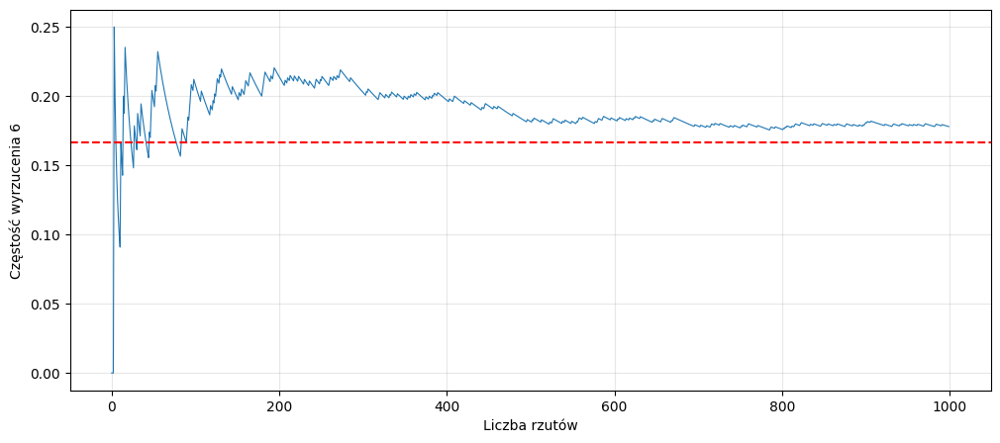

In [52]:
# Jak częstość zbliża się do prawdopodobieństwa teoretycznego wraz ze wzrostem liczby rzutów
rzuty = np.random.randint(1, 7, size=1_000)
czestosci_narastajace = np.cumsum(rzuty == 6) / np.arange(1, len(rzuty) + 1)

plt.figure(figsize=(12, 5))
plt.plot(czestosci_narastajace, linewidth=0.8)
plt.axhline(y=1/6, color='red', linestyle='--')
plt.xlabel('Liczba rzutów')
plt.ylabel('Częstość wyrzucenia 6')
plt.grid(True, alpha=0.3)
plt.show()

Im więcej razy powtórzymy eksperyment, tym bardziej **częstość** (wynik doświadczalny) zbliża się do **prawdopodobieństwa** (wartość teoretyczna). To jest tzw. **prawo wielkich liczb**.

## 1.2. Zdarzenia i operacje na zdarzeniach

Zdarzenie to podzbiór przestrzeni próby (zbioru wszystkich możliwych wyników).

### Podstawowe operacje

| Operacja | Symbol | Znaczenie | Przykład (kostka) |
|----------|--------|----------|-------------------|
| Suma (OR) | $A \cup B$ | A **lub** B (co najmniej jedno) | Parzysta LUB > 4 |
| Iloczyn (AND) | $A \cap B$ | A **i** B (oba naraz) | Parzysta I > 4 |
| Dopełnienie (NOT) | $A'$ lub $\bar{A}$ | **Nie** A | Nie parzysta = Nieparzysta |

### Wzory

**Prawdopodobieństwo sumy:**

$$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$

**Prawdopodobieństwo dopełnienia:**

$$P(\bar{A}) = 1 - P(A)$$

In [ ]:
0.66
0.50 + 0.33 - 0.16

# Dlaczego ten wzór działa:
# Lewa strona = {2,4,5,6}
# Prawa strona = {2,4,6} + {5,6} - {6}

0.67

In [55]:
# Przykład: rzut kostką
# A = wyrzucenie liczby parzystej = {2, 4, 6}
# B = wyrzucenie liczby większej niż 4 = {5, 6}

A = {2, 4, 6}       # parzyste
B = {5, 6}           # większe niż 4
omega = {1, 2, 3, 4, 5, 6}  # przestrzeń próby

In [56]:
# Suma (OR) — A lub B
A_lub_B = A | B     # w Pythonie | to suma zbiorów
print(f"A ∪ B = {A_lub_B}")
print(f"P(A ∪ B) = {len(A_lub_B)}/{len(omega)} = {len(A_lub_B)/len(omega):.4f}")

A ∪ B = {2, 4, 5, 6}
P(A ∪ B) = 4/6 = 0.6667


In [57]:
# Iloczyn (AND) — A i B
A_i_B = A & B       # w Pythonie & to iloczyn zbiorów
print(f"\nA ∩ B = {A_i_B}")
print(f"P(A ∩ B) = {len(A_i_B)}/{len(omega)} = {len(A_i_B)/len(omega):.4f}")


A ∩ B = {6}
P(A ∩ B) = 1/6 = 0.1667


In [58]:
# Dopełnienie (NOT) — nie A
nie_A = omega - A    # w Pythonie - to różnica zbiorów
print(f"\nA' = {nie_A}")
print(f"P(A') = {len(nie_A)}/{len(omega)} = {len(nie_A)/len(omega):.4f}")


A' = {1, 3, 5}
P(A') = 3/6 = 0.5000


In [61]:
# Sprawdzenie wzoru na sumę
P_A = len(A) / len(omega)
P_B = len(B) / len(omega)
P_AB = len(A_i_B) / len(omega)
print(f"\nSprawdzenie: P(A) + P(B) - P(A∩B) = {P_A} + {P_B} - {P_AB} = {P_A + P_B - P_AB:.4f}")


Sprawdzenie: P(A) + P(B) - P(A∩B) = 0.5 + 0.3333333333333333 - 0.16666666666666666 = 0.6667


In [64]:
# Zdarzenia niezalezne
# Lewa strona: {6}, p=0.167
# Prawa strona: {2,4,6}, p=0.5 x {5,6}, p=1/3
0.5*(1/3)

# Zdarzenia ktore nie sa niezalezne
# rzucamy pierwszą kostką, gdy wypadnie liczba parzysta to rzucamy drugą kostką
# Lewa strona: {2,4,6}, p=0.5
# Prawa strona:
#   - gdy wypadła liczba parzysta to rzucamy drugą kostką: {5,6}, p=1/3, 
#   - gdy wypadła liczba nie parzysta to nie rzucamy drugą kostką: {}, p=0
(0.5*(1/3) + 0.5*0) # prawd. zdarzenia B

# P(A) x P(B)
0.5 * (0.5*(1/3) + 0.5*0) 


0.08333333333333333

## 1.3. Zdarzenia niezależne

Dwa zdarzenia $A$ i $B$ są **niezależne**, jeśli wystąpienie jednego **nie wpływa** na prawdopodobieństwo drugiego.

Jeśli $A$ i $B$ są niezależne:

$$P(A \cap B) = P(A) \cdot P(B)$$

### Przykład: dwa rzuty monetą

Jakie jest prawdopodobieństwo, że w dwóch rzutach monetą wypadną dwa orły?

In [65]:
# Teoretycznie:
P_orzel = 0.5
P_dwa_orly = P_orzel * P_orzel  # zdarzenia niezależne
print(f"P(orzeł) × P(orzeł) = {P_orzel} × {P_orzel} = {P_dwa_orly}")

P(orzeł) × P(orzeł) = 0.5 × 0.5 = 0.25


In [ ]:
# 4 mozliwe wyniki: OO, OR, RO, RR
# {00} / {OO, OR, RO, RR}

In [97]:
# Symulacja: 100 000 par rzutów
n = 10_000
rzut1 = np.random.choice(['orzeł', 'reszka'], size=n)
rzut2 = np.random.choice(['orzeł', 'reszka'], size=n)

dwa_orly = np.sum((rzut1 == 'orzeł') & (rzut2 == 'orzeł'))
print(f"\nSymulacja ({n:,} prób): {dwa_orly} razy wypadły dwa orły")
print(f"Częstość = {dwa_orly/n:.4f} (oczekiwane: {P_dwa_orly})")


Symulacja (10,000 prób): 2541 razy wypadły dwa orły
Częstość = 0.2541 (oczekiwane: 0.25)


In [ ]:
# Jakie jest P(OO)?
# Wiemy ze w pierwszym rzucie był orzeł 
# {OO}, {OR}
# {OO} / {OO, OR}, p=0.5

## 1.4. Prawdopodobieństwo warunkowe

Prawdopodobieństwo warunkowe mówi nam, jakie jest prawdopodobieństwo zdarzenia $A$, **jeśli wiemy, że zaszło zdarzenie $B$**.

$$P(A|B) = \frac{P(A \cap B)}{P(B)}$$

Czytamy: "Prawdopodobieństwo A pod warunkiem B".

### Przykład: karty

Z talii 52 kart losujemy jedną kartę.
- $A$ = karta jest asem
- $B$ = karta jest czerwona (kier lub karo)

Jakie jest prawdopodobieństwo, że karta jest asem, **jeśli wiemy, że jest czerwona**?

In [98]:
# Talia kart: 52 karty, 4 kolory (2 czerwone, 2 czarne), 13 wartości
# Asy: 4 (po jednym w każdym kolorze)
# Czerwone: 26 (13 kierów + 13 kar)
# Czerwone asy: 2 (as kier + as karo)

P_A = 4 / 52        # P(as)
P_B = 26 / 52       # P(czerwona)
P_A_i_B = 2 / 52    # P(as I czerwona) = P(czerwony as)

# Prawdopodobieństwo warunkowe
P_A_pod_B = P_A_i_B / P_B

print(f"P(as) = {P_A:.4f}")
print(f"P(czerwona) = {P_B:.4f}")
print(f"P(as ∩ czerwona) = {P_A_i_B:.4f}")
print(f"\nP(as | czerwona) = {P_A_i_B:.4f} / {P_B:.4f} = {P_A_pod_B:.4f}")

P(as) = 0.0769
P(czerwona) = 0.5000
P(as ∩ czerwona) = 0.0385

P(as | czerwona) = 0.0385 / 0.5000 = 0.0769


In [100]:
# Symulacja: losujemy 100 000 kart, filtrujemy czerwone, sprawdzamy ile jest asów
kolory = ['kier', 'karo', 'trefl', 'pik']
wartosci = ['2','3','4','5','6','7','8','9','10','J','Q','K','A']

talia = [(w, k) for k in kolory for w in wartosci]
talia

[('2', 'kier'),
 ('3', 'kier'),
 ('4', 'kier'),
 ('5', 'kier'),
 ('6', 'kier'),
 ('7', 'kier'),
 ('8', 'kier'),
 ('9', 'kier'),
 ('10', 'kier'),
 ('J', 'kier'),
 ('Q', 'kier'),
 ('K', 'kier'),
 ('A', 'kier'),
 ('2', 'karo'),
 ('3', 'karo'),
 ('4', 'karo'),
 ('5', 'karo'),
 ('6', 'karo'),
 ('7', 'karo'),
 ('8', 'karo'),
 ('9', 'karo'),
 ('10', 'karo'),
 ('J', 'karo'),
 ('Q', 'karo'),
 ('K', 'karo'),
 ('A', 'karo'),
 ('2', 'trefl'),
 ('3', 'trefl'),
 ('4', 'trefl'),
 ('5', 'trefl'),
 ('6', 'trefl'),
 ('7', 'trefl'),
 ('8', 'trefl'),
 ('9', 'trefl'),
 ('10', 'trefl'),
 ('J', 'trefl'),
 ('Q', 'trefl'),
 ('K', 'trefl'),
 ('A', 'trefl'),
 ('2', 'pik'),
 ('3', 'pik'),
 ('4', 'pik'),
 ('5', 'pik'),
 ('6', 'pik'),
 ('7', 'pik'),
 ('8', 'pik'),
 ('9', 'pik'),
 ('10', 'pik'),
 ('J', 'pik'),
 ('Q', 'pik'),
 ('K', 'pik'),
 ('A', 'pik')]

In [110]:
n = 100_000
losowania = [talia[i] for i in np.random.randint(0, 52, size=n)]

# Filtrujemy tylko czerwone karty
czerwone = [(w, k) for w, k in losowania if k in ['kier', 'karo']]
asy_wsrod_czerwonych = [(w, k) for w, k in czerwone if w == 'A']

print(f"Wylosowano {len(czerwone)} czerwonych kart")
print(f"Wśród nich {len(asy_wsrod_czerwonych)} to asy")
print(f"Częstość = {len(asy_wsrod_czerwonych)/len(czerwone):.4f}")
print(f"Oczekiwane P(as|czerwona) = {2/26:.4f}")

Wylosowano 50064 czerwonych kart
Wśród nich 3813 to asy
Częstość = 0.0762
Oczekiwane P(as|czerwona) = 0.0769


In [ ]:
# Wiemy z badań klinicznych:
# P(test+ | chory) = 0.95
# P(test- | zdrowy) = 0.90

# Ale idąc do apteki po test, kolejność warunków odwraca
# P(chory | test+)

## 1.5. Prawdopodobieństwo całkowite i wzór Bayesa (intuicja)

Tabela kontyngencji: https://en.wikipedia.org/wiki/Precision_and_recall#Definition

### Przykład z życia: test medyczny

Pewna choroba dotyka **1%** populacji. Test diagnostyczny ma:
- **czułość** (sensitivity) = 95% → wykrywa chorobę u 95% chorych
- **swoistość** (specificity) = 90% → prawidłowo identyfikuje 90% zdrowych

**Pytanie:** Jeśli test jest pozytywny, jakie jest prawdopodobieństwo, że naprawdę jesteś chory?

To jest pytanie o **P(chory | test+)** — prawdopodobieństwo warunkowe!

### Wzór Bayesa

$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

In [112]:
# Dane
P_chory = 0.01           # 1% populacji jest chora
P_zdrowy = 1 - P_chory   # 99% populacji jest zdrowa
P_test_plus_chory = 0.95  # czułość: P(test+|chory)
P_test_plus_zdrowy = 0.10 # fałszywie pozytywny: P(test+|zdrowy) = 1 - swoistość

In [114]:
# Jakie jest P(test+)
0.01 * 0.95 + 0.99 * 0.10

0.1085

In [115]:
# Prawdopodobieństwo całkowite: P(test+)
P_test_plus = P_test_plus_chory * P_chory + P_test_plus_zdrowy * P_zdrowy

# Wzór Bayesa: P(chory|test+)
P_chory_pod_test_plus = (P_test_plus_chory * P_chory) / P_test_plus

print("ANALIZA TESTU MEDYCZNEGO")
print(f"P(choroba w populacji)     = {P_chory:.2%}")
print(f"Czułość testu              = {P_test_plus_chory:.2%}")
print(f"Swoistość testu            = {1 - P_test_plus_zdrowy:.2%}")
print(f"\nP(test pozytywny)          = {P_test_plus:.4f} = {P_test_plus:.2%}")
print(f"\nP(chory | test+)       = {P_chory_pod_test_plus:.4f} = {P_chory_pod_test_plus:.2%}")
print(f"\nNiespodzianka! Mimo pozytywnego testu, prawdopodobieństwo, choroby to tylko ~{P_chory_pod_test_plus:.0%}. Dlaczego?")
print(f"Ponieważ choroba jest rzadka (1%), więc fałszywie pozytywnych wyników jest bardzo dużo w porównaniu do prawdziwie pozytywnych.")

ANALIZA TESTU MEDYCZNEGO
P(choroba w populacji)     = 1.00%
Czułość testu              = 95.00%
Swoistość testu            = 90.00%

P(test pozytywny)          = 0.1085 = 10.85%

P(chory | test+)       = 0.0876 = 8.76%

Niespodzianka! Mimo pozytywnego testu, prawdopodobieństwo, choroby to tylko ~9%. Dlaczego?
Ponieważ choroba jest rzadka (1%), więc fałszywie pozytywnych wyników jest bardzo dużo w porównaniu do prawdziwie pozytywnych.


In [116]:
# Wizualizacja na przykładzie 10 000 osób
populacja = 10_000
chorych = int(populacja * P_chory)
zdrowych = populacja - chorych

# Wyniki testów
chorzy_test_plus = int(chorych * P_test_plus_chory)
chorzy_test_minus = chorych - chorzy_test_plus
zdrowi_test_plus = int(zdrowych * P_test_plus_zdrowy)
zdrowi_test_minus = zdrowych - zdrowi_test_plus

# Tabela kontyngencji
tabela = pd.DataFrame({
    'Chorzy': [chorzy_test_plus, chorzy_test_minus, chorych],
    'Zdrowi': [zdrowi_test_plus, zdrowi_test_minus, zdrowych],
    'Razem': [chorzy_test_plus + zdrowi_test_plus, 
              chorzy_test_minus + zdrowi_test_minus, 
              populacja]
}, index=['Test +', 'Test -', 'Razem'])

print(f"Tabela kontyngencji dla {populacja:,} osób:\n")
print(tabela)
print(f"\nWśród {chorzy_test_plus + zdrowi_test_plus} osób z testem '+':")
print(f"  - {chorzy_test_plus} naprawdę chorych")
print(f"  - {zdrowi_test_plus} fałszywie pozytywnych (zdrowych!)")
print(f"\nProporcja chorych wśród test+: {chorzy_test_plus}/{chorzy_test_plus + zdrowi_test_plus} = {chorzy_test_plus/(chorzy_test_plus + zdrowi_test_plus):.2%}")

Tabela kontyngencji dla 10,000 osób:

        Chorzy  Zdrowi  Razem
Test +      95     990   1085
Test -       5    8910   8915
Razem      100    9900  10000

Wśród 1085 osób z testem '+':
  - 95 naprawdę chorych
  - 990 fałszywie pozytywnych (zdrowych!)

Proporcja chorych wśród test+: 95/1085 = 8.76%


---
## Zadania do samodzielnego rozwiązania — Część 1

### Zadanie 1.1
Rzucamy dwiema kostkami. Oblicz:
- a) P(suma oczek = 7)
- b) P(suma oczek > 10)
- c) P(obie kostki pokazują tę samą wartość)

**Wskazówka:** Wypisz wszystkie możliwe pary (i, j) gdzie i, j ∈ {1,2,3,4,5,6}. Jest ich 36.

### Zadanie 1.2
Firma e-commerce wysyła **newsletter** do swoich klientów. Wśród 200 subskrybentów:
- 120 to **kobiety**, 80 to **mężczyźni**
- 45 kobiet i 20 mężczyzn **kliknęło** w link w newsletterze

Losujemy jednego subskrybenta.
- a) P(subskrybent kliknął w link)
- b) P(subskrybent kliknął w link **i** jest mężczyzną)
- c) P(subskrybent kliknął w link | subskrybent jest kobietą)
- d) Czy płeć i kliknięcie w link są zdarzeniami niezależnymi? Uzasadnij liczbowo.

### Zadanie 1.3
Test na COVID-19 ma czułość 98% i swoistość 95%. W danym mieście 5% ludzi jest zarażonych.
Oblicz P(zarażony | test pozytywny). Czy wynik Cię zaskakuje?

In [ ]:
# Miejsce na rozwiązanie Zadania 1.1
# Wskazówka: użyj pętli for do wypisania wszystkich par
liczby = [i for i in range (1, 7)]
 
kombinacja = [(i, j) for i in liczby for j in liczby]
kombinacja
 
# a) P(suma = 7)
# ile jest par, gdzie suma = 7
# 1+6, 6+1, 2+5, 5+2, 3+4, 4+3
suma_7 = [(i, j) for i in liczby for j in liczby if i + j == 7]
print("P-stwo suma = 7 wynosi:", len(suma_7)/len(kombinacja))
 
# b) P(suma > 10)
# 5+6, 6+5, 6+6
suma_wiecej_10 = [(i, j) for i in liczby for j in liczby if i + j > 10]
print("P-stwo suma > 10 wynosi:", len(suma_wiecej_10)/len(kombinacja))
 
# c) P(obie takie same)
# 1,1 2,2, ... 6,6
takie_same = [(i, j) for i in liczby for j in liczby if i == j]
print("P-stwo obu takich samych liczb wynosi:", len(takie_same)/len(kombinacja))

P-stwo suma = 7 wynosi: 0.16666666666666666
P-stwo suma > 10 wynosi: 0.08333333333333333
P-stwo obu takich samych liczb wynosi: 0.16666666666666666


In [119]:
all_possibilities = [(i, j) for i in range(1, 7) for j in range(1, 7)]
all_possibilities_count = len(all_possibilities)
print(f"Wszystkie mozliwosci (ile = {all_possibilities_count}):")
print(all_possibilities)

# a) P(suma = 7)
# mozliwe przypadki: (1,6), (2,5), (3,4), (4,3), (5,2), (6,1) -> ile = 6
# prawdopodobienstwo 6/36 = 1/6 = 0.16666667
sum_7 = [o for o in all_possibilities if o[0] + o[1] == 7]
p_sum7 = len(sum_7) / all_possibilities_count
print(f"P(suma = 7) = {p_sum7}")

# b) P(suma > 10)
# mozliwe sumy: 11 i 12 -> mozliwe przypadki: (5,6), (6,5), (6,6) -> ile = 3
# prawdopodobienstwo 3/36 = 1/12 = 0,08333333
sum_gt_10 = [o for o in all_possibilities if o[0] + o[1] > 10]
p_sum_gt_10 = len(sum_gt_10) / all_possibilities_count
print(f"P(suma > 10) = {p_sum_gt_10}")

# c) P(obie takie same)
# mozliwe przypadki: (1,1), (2,2), (3,3), (4,4), (5,5), (6,6) -> ile = 6
# prawdopodobienstwo 6/36 = 1/6 = 0.16666667
equal = [o for o in all_possibilities if o[0] == o[1]]
p_equal = len(equal) / all_possibilities_count
print(f"P(obie takie same) = {p_equal}")

Wszystkie mozliwosci (ile = 36):
[(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (6, 1), (6, 2), (6, 3), (6, 4), (6, 5), (6, 6)]
P(suma = 7) = 0.16666666666666666
P(suma > 10) = 0.08333333333333333
P(obie takie same) = 0.16666666666666666


In [118]:
3/36

0.08333333333333333

In [121]:
# Miejsce na rozwiązanie Zadania 1.2
# calkowita ilosc subskrybentow
subscribers_woman = 120
subscribers_man = 80
subscribers_total = subscribers_woman + subscribers_man
# ilosc subskrybentow ktorzy klikneli
clicked_woman = 45
clicked_man = 20
clicked_total = clicked_woman + clicked_man

# a) P(kliknal)
#    czyli ilu subskrybentow newslettera kliknelo w link: 65 / 200
p_click = clicked_total / subscribers_total
print("a) P(kliknal) = ", p_click)

# b) P(kliknal i jest mezczyzna)
#    czyli ilu mezczyzn bedacych subksrybentami kliknelo w link: 20 / 200
p_click_and_man = clicked_man / subscribers_total
print("b) P(kliknal i mezczyzna) = ", p_click_and_man)

# c) P(kliknal | kobieta) - prawdopodobienstwo warunkowe
#    czyli jakie jest prawdopodobienstwo ze subsrybent kliknal jezeli wiemy ze jest kobieta
#    czyli sprawdzamy ile kobiet kliknelo sposrod wszystkich kobiet: 45 / 120
# P(A | B) = P(A i B) / P(B)
p_click_given_woman = clicked_woman / subscribers_woman
print("c) P(kliknal | kobieta) = ", p_click_given_woman)

# d) sprawdzenie niezaleznosci: Czy plec i klikniecie w link są zdarzeniami niezaleznymi?
print("d) sprawdzenie niezaleznosci: P(A ∩ B) = P(A) * P(B)")
# P(A) = prawdopodobienstwo ze subskrybent kliknie
# P(B) = prawdopodobienstwo ze subskrybent to np. mezczyzna
left_side = p_click_and_man     # to juz liczylismy w pkt B
right_side = p_click * (subscribers_man / subscribers_total)
print("   lewa strona: P(A ∩ B) = ", left_side)
print("   prawa strona: P(A) * P(B) = ", right_side)
# print("   -------------------------------------------------")
# if left_side == right_side:
#     print("   Zdarzenia sa niezalezne")
# else:
#     print("   Zdarzenia NIE sa niezalezne")
print("   Zdarzenia NIE sa niezalezne")

a) P(kliknal) =  0.325
b) P(kliknal i mezczyzna) =  0.1
c) P(kliknal | kobieta) =  0.375
d) sprawdzenie niezaleznosci: P(A ∩ B) = P(A) * P(B)
   lewa strona: P(A ∩ B) =  0.1
   prawa strona: P(A) * P(B) =  0.13
   Zdarzenia NIE sa niezalezne


In [122]:
# Miejsce na rozwiązanie Zadania 1.3
# Wskazówka: użyj wzoru Bayesa, tak jak w przykładzie z testem medycznym
P_zarazony = 0.05
P_zdrowy = 0.95
P_test_plus_zarazony = 0.98
P_test_plus_zdrowy = 0.05
P_test_plus = P_test_plus_zarazony * P_zarazony + P_test_plus_zdrowy * P_zdrowy
P_zarazony_pod_test_plus = (P_test_plus_zarazony * P_zarazony) / P_test_plus

---
# Część 2: Rozkłady prawdopodobieństwa

## 2.1. Rozkłady dyskretne (skokowe) vs. ciągłe

| Cecha | Rozkład dyskretny | Rozkład ciągły |
|-------|-------------------|----------------|
| Wartości | Policzalne (0, 1, 2, ...) | Dowolne z przedziału |
| Funkcja | P(X = x) — prawdopodobieństwo | f(x) — gęstość |
| Przykłady | Liczba klientów, rzut kostką | Wzrost, temperatura, czas |
| Suma prawdopodobieństw | $\sum P(X=x) = 1$ | $\int f(x)\,dx = 1$ |

## 2.2. Rozkład dwumianowy (binomial)

Wykonujemy $n$ niezależnych prób, w każdej szansa sukcesu = $p$.

Jaki jest rozkład **liczby sukcesów**?

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

gdzie $\binom{n}{k} = \frac{n!}{k!(n-k)!}$ — symbol Newtona ("n po k")

**Parametry:** $n$ (liczba prób), $p$ (prawdopodobieństwo sukcesu)

**Średnia:** $\mu = n \cdot p$

**Odchylenie standardowe:** $\sigma = \sqrt{n \cdot p \cdot (1-p)}$

In [128]:
# ! to matematyczna silnia
# 5! = 1*2*3*4*5
# 3! = 1*2*3
import math
math.factorial(3)
math.factorial(5)

math.factorial(3) / (math.factorial(1) * math.factorial(2))

3.0

In [124]:
# Rzucamy 3 monetami. Jakie jest prawd. wyrzucenia 1 orła?
# X - ilośc orłów, P(X = 1)?
# P(Orzel) = P(Reszka) = 0.5

n=3 # ilosc wszystkich rzutów
p=0.5 # P(Orzel)
k=1 # ilosc orłów
1-p # P(reszka)
n-k # ilość reszek

p**k * (1-p)**(n-k)

# ORR, ROR, RRO - to nas interesuje
# wszystkie mozliwe zdarzenia = 8
# spodziewamy sie 3/8 = 0.375

3* p**k * (1-p)**(n-k)

0.375

In [131]:
# Przykład: Rzucamy monetą 20 razy. Ile razy wypadnie orzeł?
n = 20       # liczba rzutów
p = 0.5      # prawdopodobieństwo orła

# Wartości k od 0 do 20
k_values = np.arange(0, n + 1)

# Prawdopodobieństwa z rozkładu dwumianowego
prawdopodobienstwa = stats.binom.pmf(k_values, n, p)
[float(round(p, 5)) for p in prawdopodobienstwa]

[0.0,
 2e-05,
 0.00018,
 0.00109,
 0.00462,
 0.01479,
 0.03696,
 0.07393,
 0.12013,
 0.16018,
 0.1762,
 0.16018,
 0.12013,
 0.07393,
 0.03696,
 0.01479,
 0.00462,
 0.00109,
 0.00018,
 2e-05,
 0.0]

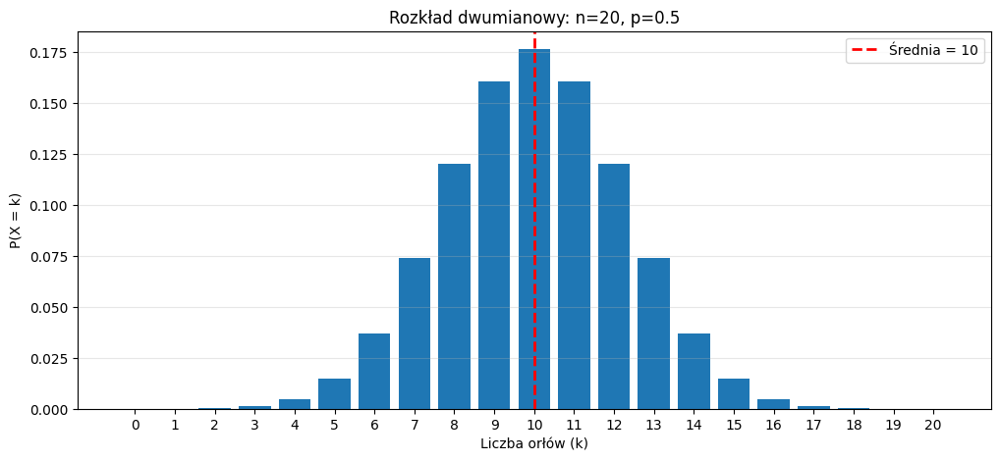

In [132]:
plt.figure(figsize=(12, 5))
plt.bar(k_values, prawdopodobienstwa)
plt.xlabel('Liczba orłów (k)')
plt.ylabel('P(X = k)')
plt.title(f'Rozkład dwumianowy: n={n}, p={p}')
plt.xticks(k_values)
plt.grid(axis='y', alpha=0.3)

# Zaznaczenie średniej
srednia = n * p
plt.axvline(x=srednia, color='red', linestyle='--', linewidth=2,  label=f'Średnia = {srednia:.0f}')
plt.legend()
plt.show()

In [133]:
print(f"Średnia liczba orłów: {srednia}")
print(f"Odchylenie standardowe: {np.sqrt(n * p * (1-p)):.2f}")
print(f"P(dokładnie 10 orłów) = {stats.binom.pmf(10, n, p):.4f}")
print(f"P(co najmniej 15 orłów) = {1 - stats.binom.cdf(14, n, p):.4f}")

Średnia liczba orłów: 10.0
Odchylenie standardowe: 2.24
P(dokładnie 10 orłów) = 0.1762
P(co najmniej 15 orłów) = 0.0207


In [136]:
# Interaktywny wykres: jak zmiana p i n wpływa na kształt rozkładu dwumianowego?
fig = go.Figure()

# Dodajemy serie dla różnych wartości p (przy n=20)
for p_val in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    k_vals = np.arange(0, 1001)
    probs = stats.binom.pmf(k_vals, 1000, p_val)
    fig.add_trace(go.Bar(
        x=k_vals, y=probs, name=f'p = {p_val}',
        visible=(p_val == 0.5),  # domyślnie widoczny tylko p=0.5
        marker_color=px.colors.qualitative.Set2[int(p_val * 100) % 8]
    ))

# Suwak do wyboru p
steps = []
for i, p_val in enumerate([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]):
    visible = [False] * 9
    visible[i] = True
    steps.append(dict(
        method='update',
        args=[{'visible': visible}],
        label=f'{p_val}'
    ))

fig.update_layout(
    sliders=[dict(active=4, steps=steps, currentvalue=dict(prefix='p = '))],
    title='Rozkład dwumianowy (n=20) — wpływ parametru p',
    xaxis_title='Liczba sukcesów (k)',
    yaxis_title='P(X = k)',
    template='plotly_white',
    height=500
)
fig.show()

## 2.3. Rozkład normalny (Gaussa)

"Najpopularniejszy" rozkład w statystyce! Wiele zjawisk naturalnych ma rozkład zbliżony do normalnego.

**Funkcja gęstości:**

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

**Parametry:**
- $\mu$ — średnia (środek rozkładu)
- $\sigma$ — odchylenie standardowe (szerokość rozkładu)

**Zapis:** $X \sim N(\mu, \sigma^2)$

### Reguła 68-95-99.7 (reguła trzech sigma)

- ~68% danych mieści się w przedziale $[\mu - \sigma,\ \mu + \sigma]$
- ~95% danych mieści się w przedziale $[\mu - 2\sigma,\ \mu + 2\sigma]$
- ~99.7% danych mieści się w przedziale $[\mu - 3\sigma,\ \mu + 3\sigma]$

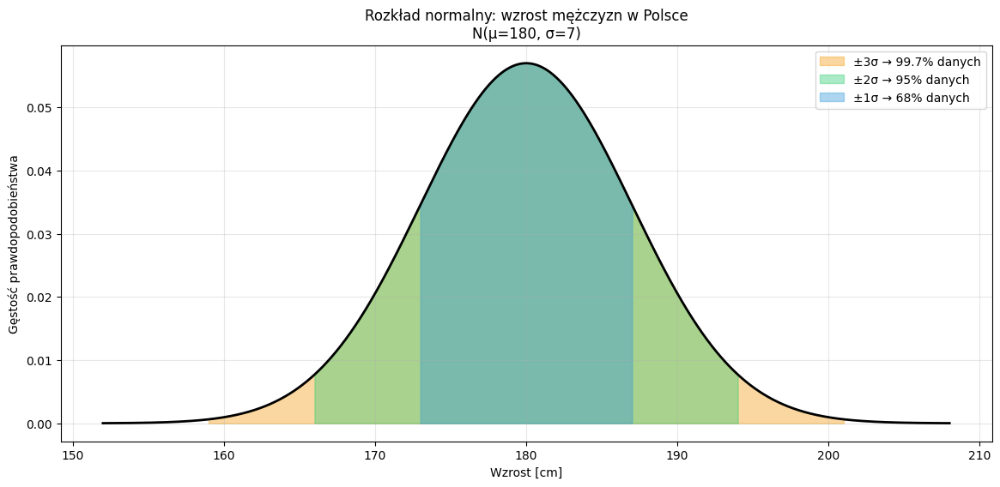

In [137]:
# Wizualizacja rozkładu normalnego z regułą 3 sigma
mu = 180      # średni wzrost Polaka [cm]
sigma = 7     # odchylenie standardowe

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = stats.norm.pdf(x, mu, sigma)

plt.figure(figsize=(14, 6))
plt.plot(x, y, 'k-', linewidth=2)

# Kolorowanie obszarów
kolory = ['#3498db', '#2ecc71', '#f39c12']
etykiety = ['68%', '95%', '99.7%']
sigmy = [1, 2, 3]

for i in range(2, -1, -1):  # rysujemy od największego do najmniejszego
    s = sigmy[i]
    x_fill = np.linspace(mu - s*sigma, mu + s*sigma, 500)
    y_fill = stats.norm.pdf(x_fill, mu, sigma)
    plt.fill_between(x_fill, y_fill, alpha=0.4, color=kolory[i], 
                     label=f'±{s}σ → {etykiety[i]} danych')

plt.xlabel('Wzrost [cm]')
plt.ylabel('Gęstość prawdopodobieństwa')
plt.title(f'Rozkład normalny: wzrost mężczyzn w Polsce\nN(μ={mu}, σ={sigma})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [138]:
print(f"Średnia: {mu} cm")
print(f"68% mężczyzn ma wzrost między {mu-sigma} a {mu+sigma} cm")
print(f"95% mężczyzn ma wzrost między {mu-2*sigma} a {mu+2*sigma} cm")
print(f"99.7% mężczyzn ma wzrost między {mu-3*sigma} a {mu+3*sigma} cm")

Średnia: 180 cm
68% mężczyzn ma wzrost między 173 a 187 cm
95% mężczyzn ma wzrost między 166 a 194 cm
99.7% mężczyzn ma wzrost między 159 a 201 cm


In [139]:
# Interaktywny wykres: wpływ parametrów μ i σ na rozkład normalny
x_range = np.linspace(100, 260, 500)

mu_values = list(range(150, 201))    # μ od 150 do 200
sigma_values = list(range(1, 21))    # σ od 1 do 20

mu_default = 180
sigma_default = 7

fig = go.Figure()

# Tworzymy ślady dla każdej kombinacji (mu, sigma)
for mu_val in mu_values:
    for sigma_val in sigma_values:
        visible = (mu_val == mu_default and sigma_val == sigma_default)
        fig.add_trace(go.Scatter(
            x=x_range,
            y=stats.norm.pdf(x_range, mu_val, sigma_val),
            mode='lines',
            line=dict(color='#3498db', width=2.5),
            visible=visible,
            name=f'N({mu_val}, {sigma_val}²)'
        ))

n_sigma = len(sigma_values)
n_mu = len(mu_values)

# Suwak dla μ
mu_steps = []
for i, mu_val in enumerate(mu_values):
    j_sigma = sigma_values.index(sigma_default)
    vis = [False] * (n_mu * n_sigma)
    vis[i * n_sigma + j_sigma] = True
    mu_steps.append(dict(
        method='update',
        args=[{'visible': vis},
              {'title': f'Rozkład normalny N(μ={mu_val}, σ={sigma_default})'}],
        label=str(mu_val)
    ))

# Suwak dla σ
sigma_steps = []
for j, sigma_val in enumerate(sigma_values):
    i_mu = mu_values.index(mu_default)
    vis = [False] * (n_mu * n_sigma)
    vis[i_mu * n_sigma + j] = True
    sigma_steps.append(dict(
        method='update',
        args=[{'visible': vis},
              {'title': f'Rozkład normalny N(μ={mu_default}, σ={sigma_val})'}],
        label=str(sigma_val)
    ))

fig.update_layout(
    sliders=[
        dict(active=mu_values.index(mu_default), pad=dict(t=60),
             steps=mu_steps, currentvalue=dict(prefix='μ = '), x=0.0, len=1.0, y=0),
        dict(active=sigma_values.index(sigma_default), pad=dict(t=20),
             steps=sigma_steps, currentvalue=dict(prefix='σ = '), x=0.0, len=1.0, y=-0.15)
    ],
    title=f'Rozkład normalny N(μ={mu_default}, σ={sigma_default})',
    xaxis_title='Wartość', yaxis_title='Gęstość',
    template='plotly_white', height=800,
    margin=dict(b=120)
)
fig.show()

In [142]:
# Praktyczne pytania o rozkład normalny

mu = 180
sigma = 7

# Pytanie 1: Jaki % mężczyzn ma wzrost poniżej 160 cm?
p1 = stats.norm.cdf(160, mu, sigma)
print(f"P(wzrost < 160) = {p1:.4f} = {p1:.2%}")

# Pytanie 2: Jaki % mężczyzn ma wzrost powyżej 185 cm?
p2 = 1 - stats.norm.cdf(185, mu, sigma)
print(f"P(wzrost > 185) = {p2:.4f} = {p2:.2%}")

# Pytanie 3: Jaki % mężczyzn ma wzrost między 165 a 180 cm?
p3 = stats.norm.cdf(180, mu, sigma) - stats.norm.cdf(165, mu, sigma)
print(f"P(165 < wzrost < 180) = {p3:.4f} = {p3:.2%}")

# Pytanie 4: Poniżej jakiego wzrostu jest 10% najniższych mężczyzn?
wzrost_10 = stats.norm.ppf(0.10, mu, sigma)
print(f"\n10% najniższych mężczyzn ma wzrost poniżej {wzrost_10:.1f} cm")

# Pytanie 5: Powyżej jakiego wzrostu jest 5% najwyższych mężczyzn?
wzrost_95 = stats.norm.ppf(0.95, mu, sigma)
print(f"5% najwyższych mężczyzn ma wzrost powyżej {wzrost_95:.1f} cm")

P(wzrost < 160) = 0.0021 = 0.21%
P(wzrost > 185) = 0.2375 = 23.75%
P(165 < wzrost < 180) = 0.4839 = 48.39%

10% najniższych mężczyzn ma wzrost poniżej 171.0 cm
5% najwyższych mężczyzn ma wzrost powyżej 191.5 cm


### Dystrybuanta i funkcja kwantylowa

Dwa kluczowe narzędzia, które pojawiają się przy pracy z rozkładami:

**Dystrybuanta** (CDF — *Cumulative Distribution Function*) odpowiada na pytanie:

> Jakie jest prawdopodobieństwo, że zmienna losowa przyjmie wartość **mniejszą lub równą** $x$?

$$F(x) = P(X \leq x)$$

Przykład: *Jaki procent mężczyzn ma wzrost ≤ 185 cm?* → `stats.norm.cdf(185, 180, 7)`

---

**Funkcja kwantylowa** (PPF — *Percent Point Function*) to **odwrotność dystrybuanty**. Odpowiada na pytanie:

> Poniżej jakiej wartości znajduje się dany **procent** obserwacji?

$$F^{-1}(q) = x \quad \text{taki, że } P(X \leq x) = q$$

Przykład: *Poniżej jakiego wzrostu jest 10% najniższych mężczyzn?* → `stats.norm.ppf(0.10, 180, 7)`

---

| Funkcja | Pytanie | W scipy |
|---------|---------|---------|
| **CDF** (dystrybuanta) | Mam wartość $x$ → jaki % jest poniżej? | `stats.norm.cdf(x, μ, σ)` |
| **PPF** (kwantyl / odwrotność CDF) | Mam procent $q$ → jaka wartość? | `stats.norm.ppf(q, μ, σ)` |
| **PDF** (gęstość) lub **PMF** | Jak "gęste" są obserwacje w punkcie $x$? | `stats.norm.pdf(x, μ, σ)` |
| **RVS** (losowanie) | Wygeneruj losowe wartości z rozkładu | `stats.norm.rvs(μ, σ, size=n)` |

In [153]:
stats.norm.rvs(180, 7, 10)

array([176.90847752, 188.42354612, 188.14529959, 175.04462849,
       176.03916871, 179.79139791, 173.47599249, 179.93473125,
       181.81658853, 187.15473081])

## 2.4. Standardowy rozkład normalny

Standardowy rozkład normalny to rozkład o średniej $\mu = 0$ i odchyleniu $\sigma = 1$, oznaczany $N(0, 1)$.

Każdy rozkład normalny można **standaryzować** przekształceniem:

$$Z = \frac{X - \mu}{\sigma}$$

Zmienna $Z$ mówi nam, **o ile odchyleń standardowych** wartość $X$ odbiega od średniej.

### Po co standaryzujemy?

1. **Porównywanie wyników z różnych skal** — dzięki standaryzacji możemy porównywać rzeczy mierzone w zupełnie innych jednostkach. Np. student uzyskał 72 pkt z matematyki (średnia klasy 65, odchylenie 10) i 85 pkt z historii (średnia klasy 78, odchylenie 5). Który wynik jest relatywnie lepszy? Standaryzujemy: $Z_{mat} = (72-65)/10 = 0.7$, $Z_{hist} = (85-78)/5 = 1.4$ — historia wypada relatywnie lepiej!

2. **Korzystanie z tablic i wzorów** — wiele wzorów statystycznych (np. przedziały ufności, testy hipotez) opiera się na rozkładzie $N(0, 1)$. Standaryzacja pozwala sprowadzić dowolny rozkład normalny do jednego, standardowego.

3. **Wykrywanie wartości nietypowych (outlierów)** — jeśli $|Z| > 2$, wartość jest dość nietypowa; jeśli $|Z| > 3$ — ekstremalnie rzadka.

In [154]:
# Standaryzacja na przykładzie wzrostu
mu = 180
sigma = 7

wzrosty = [165, 173, 180, 187, 200]

print("Wzrost [cm] | Z-score | Interpretacja")
print("-" * 60)
for w in wzrosty:
    z = (w - mu) / sigma
    if abs(z) < 1:
        opis = "typowy (w 1σ od średniej)"
    elif abs(z) < 2:
        opis = "dość nietypowy (1-2σ od średniej)"
    elif abs(z) < 3:
        opis = "bardzo nietypowy (2-3σ od średniej)"
    else:
        opis = "EKSTREMALNY (>3σ od średniej)"
    print(f"    {w:>3}     |  {z:+.2f}  | {opis}")

Wzrost [cm] | Z-score | Interpretacja
------------------------------------------------------------
    165     |  -2.14  | bardzo nietypowy (2-3σ od średniej)
    173     |  -1.00  | dość nietypowy (1-2σ od średniej)
    180     |  +0.00  | typowy (w 1σ od średniej)
    187     |  +1.00  | dość nietypowy (1-2σ od średniej)
    200     |  +2.86  | bardzo nietypowy (2-3σ od średniej)


In [155]:
stats.norm.cdf(2)

np.float64(0.9772498680518208)

### Popularne rozkłady prawdopodobieństwa — ściągawka

Poza rozkładem dwumianowym i normalnym, w praktyce spotykamy wiele innych rozkładów. Oto kilka najważniejszych:

| Rozkład | Typ | Kiedy go stosujemy? | Przykład z życia | scipy.stats |
|---------|-----|---------------------|------------------|-------------|
| **Dwumianowy** (Binomial) | Dyskretny | Ile sukcesów w $n$ próbach? | Ile e-maili otworzy 100 klientów? | [binom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html) |
| **Poissona** | Dyskretny | Ile zdarzeń w ustalonym czasie/obszarze? | Ile reklamacji wpływa dziennie? | [poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html) |
| **Normalny** (Gaussa) | Ciągły | Dane skupione wokół średniej | Wzrost, wyniki egzaminów, błędy pomiarowe | [norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html) |
| **t-Studenta** | Ciągły | Małe próby, nieznane σ | Przedziały ufności, testy t | [t](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html) |
| **Wykładniczy** | Ciągły | Czas do następnego zdarzenia | Czas między awariami maszyny | [expon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html) |
| **Chi-kwadrat** ($\chi^2$) | Ciągły | Testowanie niezależności, dopasowania | Czy płeć wpływa na wybór produktu? | [chi2](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) |
| **Jednostajny** | Ciągły/Dyskretny | Wszystkie wartości jednakowo prawdopodobne | Losowanie numeru w loterii | [uniform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html) |

Pełna lista rozkładów dostępnych w scipy: [scipy.stats — dokumentacja](https://docs.scipy.org/doc/scipy/reference/stats.html)

---
## Zadania do samodzielnego rozwiązania — Część 2

### Zadanie 2.1
Na egzaminie 40 pytań z 4 odpowiedziami (jedna poprawna). Student odpowiada losowo.
- a) Jaki rozkład ma liczba poprawnych odpowiedzi? Podaj parametry.
- b) Ile poprawnych odpowiedzi student uzyska średnio?
- c) Jakie jest P(student odpowie poprawnie na co najmniej 15 pytań)?
- d) Narysuj rozkład.

### Zadanie 2.2
Czas dojazdu do pracy ma rozkład normalny ze średnią 35 minut i odchyleniem 8 minut.
- a) P(dojazd < 25 minut)
- b) P(dojazd > 50 minut)
- c) P(30 < dojazd < 40 minut)
- d) O której najpóźniej musisz wyjść, żeby z 95% pewnością zdążyć na spotkanie o 9:00?

### Zadanie 2.3 — Analiza wynagrodzeń w firmie
Wynagrodzenia w pewnej firmie mają rozkład normalny $N(6500, 1200)$ (średnia 6 500 zł, odchylenie 1 200 zł).

Wygeneruj próbę 500 „pracowników" (`stats.norm.rvs(6500, 1200, size=500)`), a następnie:

- a) Narysuj **histogram** wyników z nałożoną krzywą gęstości teoretycznej.
- b) Oblicz **średnią i odchylenie standardowe** w próbie — porównaj z parametrami rozkładu (6500 i 1200).
- c) Jaki **procent pracowników** zarabia powyżej 8 000 zł? Oblicz to:
  - w wygenerowanej próbie (policz ile obserwacji > 8000)
  - teoretycznie, korzystając z dystrybuanty (`1 - stats.norm.cdf(8000, 6500, 1200)`)
- d) Poniżej jakiej kwoty zarabia **25% najgorzej opłacanych** pracowników? (użyj `stats.norm.ppf`)
- e) **Standaryzuj** dane (oblicz Z-score dla każdej obserwacji). Narysuj histogram Z-score'ów — powinien przypominać $N(0,1)$.

c) P(X >= 15) = 0.05443724801863481


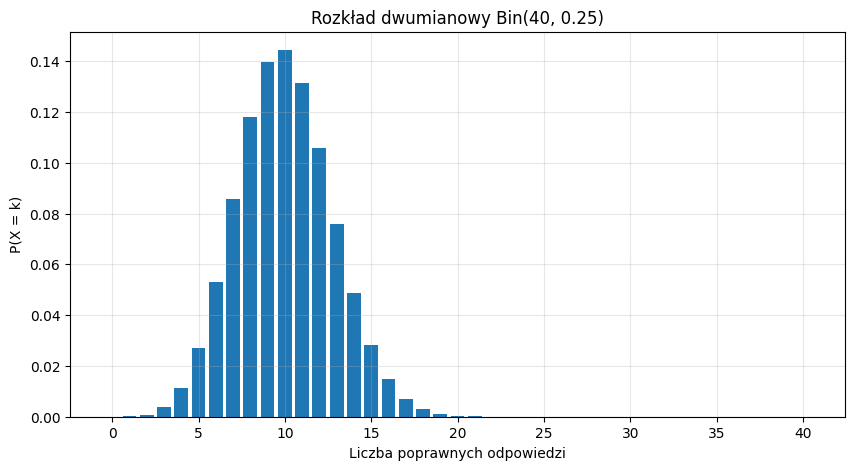

In [157]:
# Miejsce na rozwiązanie Zadania 2.1
# a) rozkład dwumianowy
n = 40
p = 0.25

# b)
n*p # 1 sposób ze wzzoru poznanego wcześniej
stats.binom.mean(n,p) # 2 sposób za pomocą gotowej funkcji
 
# c) prawdopodobieństwo co najmniej 15 poprawnych odpowiedzi
p_ge_15 = 1 - stats.binom.cdf(14, n, p)
print("c) P(X >= 15) =", p_ge_15)
 
# d) wykres rozkładu
x = np.arange(0, n + 1)
y = stats.binom.pmf(x, n, p)
 
plt.figure(figsize=(10, 5))
plt.bar(x, y)
plt.xlabel("Liczba poprawnych odpowiedzi")
plt.ylabel("P(X = k)")
plt.title("Rozkład dwumianowy Bin(40, 0.25)")
plt.grid(True, alpha=0.3)
plt.show()
 

In [ ]:
# Miejsce na rozwiązanie Zadania 2.2
# Czas dojazdu do pracy ma rozkład normalny ze średnią 35 minut i odchyleniem 8 minut.
# - a) P(dojazd < 25 minut)
# - b) P(dojazd > 50 minut)
# - c) P(30 < dojazd < 40 minut)
# - d) O której najpóźniej musisz wyjść, żeby z 95% pewnością zdążyć na spotkanie o 9:00?

mu=35
sigma=8

p_a = stats.norm.cdf(25, loc=mu, scale=sigma)
print(p_a)

p_b = 1 - stats.norm.cdf(50, loc=mu, scale=sigma)
print(p_b)

p_c = stats.norm.cdf(40, loc=mu, scale=sigma) - stats.norm.cdf(30, loc=mu, scale=sigma)
print(p_c)

# 
stats.norm.ppf(0.95, mu, sigma)
# nalezy wyjść z domu najpóźniej 8:11

0.10564977366685535
0.030396361765261393
0.4680289419025989


np.float64(48.15882901561177)

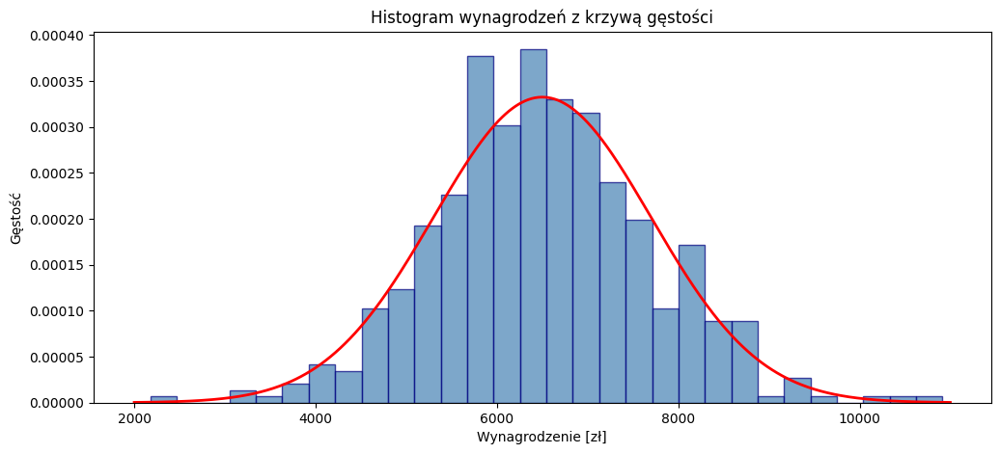

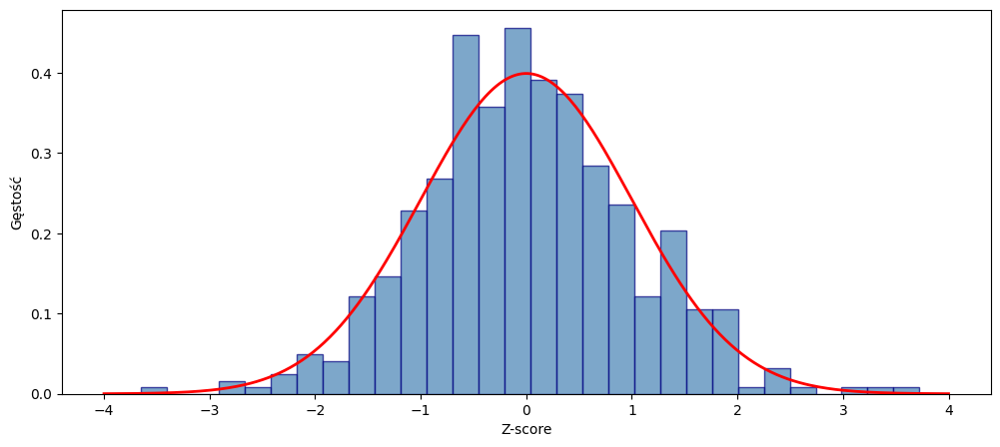

In [166]:
# Miejsce na rozwiązanie Zadania 2.3
# Zadanie 2.3a
dane = stats.norm.rvs(6500, 1200, size=500)
plt.figure(figsize=(12, 5))
plt.hist(dane, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='navy')
x = np.linspace(2000, 11000, 500)
plt.plot(x, stats.norm.pdf(x, 6500, 1200), 'r-', linewidth=2)
plt.xlabel('Wynagrodzenie [zł]')
plt.ylabel('Gęstość')
plt.title('Histogram wynagrodzeń z krzywą gęstości')
plt.show()

# Zadanie 2.3b
np.mean(dane)
np.std(dane, ddof=1)

# Zadanie 2.3c
np.mean(dane > 8000) * 100
(1 - stats.norm.cdf(8000, 6500, 1200)) * 100

# Zadanie 2.3d
stats.norm.ppf(0.25, 6500, 1200)

# Zadanie 2.3e
z_scores = (dane - np.mean(dane)) / np.std(dane, ddof=1)
plt.figure(figsize=(12, 5))
plt.hist(z_scores, bins=30, density=True, alpha=0.7, color='steelblue', edgecolor='navy')
x_z = np.linspace(-4, 4, 300)
plt.plot(x_z, stats.norm.pdf(x_z, 0, 1), 'r-', linewidth=2)
plt.xlabel('Z-score')
plt.ylabel('Gęstość')
plt.show()

---
# Część 3: Centralne Twierdzenie Graniczne (CTG)

## Najważniejsze twierdzenie w statystyce!

**Centralne Twierdzenie Graniczne** mówi, że:

> Niezależnie* od rozkładu populacji, rozkład **średniej z próby** zbliża się do rozkładu **normalnego**, gdy wielkość próby $n$ rośnie.

Formalnie: jeśli $X_1, X_2, ..., X_n$ to niezależne zmienne o średniej $\mu$ i odchyleniu $\sigma$, to:

$$\bar{X} \xrightarrow{d} N\left(\mu,\ \frac{\sigma^2}{n}\right) \quad \text{gdy } n \to \infty$$

**Dlaczego to ważne?**
- Pozwala stosować rozkład normalny nawet gdy dane **nie** mają rozkładu normalnego
- Jest fundamentem przedziałów ufności i testów statystycznych
- Działa już dla $n \geq 30$ (w praktyce)

*Uwaga — CTG nie działa z każdym rozkładem!

CTG wymaga, aby rozkład populacji miał **skończoną wariancję** ($\sigma^2 < \infty$). Istnieją rozkłady, dla których ten warunek nie jest spełniony i CTG **nie** ma zastosowania, np.:
- **Rozkład Cauchy'ego** — nie posiada ani średniej, ani wariancji. Średnia z próby *nie* zbliża się do rozkładu normalnego, niezależnie od wielkości $n$.
- **Rozkłady z „ciężkimi ogonami"** (*heavy-tailed*) o nieskończonej wariancji — np. niektóre rozkłady stabilne Lévy'ego.

W praktyce takie rozkłady pojawiają się np. w modelowaniu rynków finansowych (ekstremalne wahania kursów) czy w fizyce (procesy anomalnej dyfuzji).

In [163]:
N_powtorzen = 10_000
wielkosc_proby = [1, 2, 5, 10, 30, 100]

fig = go.Figure()

for n in wielkosc_proby:
    srednie = [np.mean(np.random.randint(1, 7, size=n)) for _ in range(N_powtorzen)]
    fig.add_trace(go.Histogram(
        x=srednie, nbinsx=60, histnorm='probability density',
        name=f'n = {n}',
        visible=(n == 1),
        marker_color='steelblue', opacity=0.7
    ))
    # krzywa normalna dopasowana
    if n >= 2:
        mu_teor = 3.5
        sigma_teor = np.sqrt(35/12) / np.sqrt(n)
        x_norm = np.linspace(0.5, 6.5, 300)
        fig.add_trace(go.Scatter(
            x=x_norm, y=stats.norm.pdf(x_norm, mu_teor, sigma_teor),
            mode='lines', name=f'N(3.5, {sigma_teor:.2f}²)',
            visible=(n == 1),
            line=dict(color='red', width=2.5)
        ))
    else:
        fig.add_trace(go.Scatter(x=[], y=[], visible=False, name=''))

# Przyciski do przełączania n
buttons = []
for i, n in enumerate(wielkosc_proby):
    visible = [False] * (len(wielkosc_proby) * 2)
    visible[i * 2] = True      # histogram
    visible[i * 2 + 1] = True  # krzywa
    buttons.append(dict(
        method='update',
        args=[{'visible': visible}],
        label=f'n = {n}'
    ))

fig.update_layout(
    updatemenus=[dict(type='buttons', direction='right', x=0.5, xanchor='center', y=1.15,
                      buttons=buttons, showactive=True)],
    title='Centralne Twierdzenie Graniczne: rozkład średniej z n kostek',
    xaxis_title='Średnia z n kostek', yaxis_title='Gęstość',
    xaxis=dict(range=[0.5, 6.5]),
    template='plotly_white', height=500,
    bargap=0.05
)
fig.show()

print("Obserwacja: nawet dla rozkładu jednostajnego (kostka),")
print("średnia z próby ma rozkład coraz bardziej zbliżony do normalnego!")
print("Dla n=30 rozkład jest już prawie idealnie normalny.")

Obserwacja: nawet dla rozkładu jednostajnego (kostka),
średnia z próby ma rozkład coraz bardziej zbliżony do normalnego!
Dla n=30 rozkład jest już prawie idealnie normalny.


In [ ]:
# Stawiamy 1000 zł na rzut kostką
# I mozemy wygrac 5950 zł
# Mamy 1/6 na wygraną

In [164]:
# CTG z rozkładem wykładniczym — jeszcze bardziej skrajny przypadek
fig = go.Figure()

for n in wielkosc_proby:
    srednie = [np.mean(np.random.exponential(scale=5, size=n)) for _ in range(N_powtorzen)]
    fig.add_trace(go.Histogram(
        x=srednie, nbinsx=60, histnorm='probability density',
        name=f'n = {n}',
        visible=(n == 1),
        marker_color='#2ecc71', opacity=0.7
    ))
    if n >= 2:
        x_norm = np.linspace(min(srednie), max(srednie), 300)
        fig.add_trace(go.Scatter(
            x=x_norm, y=stats.norm.pdf(x_norm, 5, 5/np.sqrt(n)),
            mode='lines', name=f'N(5, {5/np.sqrt(n):.2f}²)',
            visible=(n == 1),
            line=dict(color='red', width=2.5)
        ))
    else:
        fig.add_trace(go.Scatter(x=[], y=[], visible=False, name=''))

buttons = []
for i, n in enumerate(wielkosc_proby):
    visible = [False] * (len(wielkosc_proby) * 2)
    visible[i * 2] = True
    visible[i * 2 + 1] = True
    buttons.append(dict(method='update', args=[{'visible': visible}], label=f'n = {n}'))

fig.update_layout(
    updatemenus=[dict(type='buttons', direction='right', x=0.5, xanchor='center', y=1.15,
                      buttons=buttons, showactive=True)],
    title='CTG: rozkład wykładniczy (BARDZO skośny!) → średnia i tak staje się normalna',
    xaxis_title='Średnia z n wartości wykładniczych', yaxis_title='Gęstość',
    template='plotly_white', height=500,
    bargap=0.05
)
fig.show()

print("Nawet bardzo skośny rozkład wykładniczy →")
print("średnia z próby staje się normalna dla dużych n!")

Nawet bardzo skośny rozkład wykładniczy →
średnia z próby staje się normalna dla dużych n!


### Podsumowanie CTG

Kluczowe wnioski:
1. Średnia z próby ma rozkład **w przybliżeniu normalny** $N(\mu, \sigma^2/n)$
2. Im większa próba ($n$), tym rozkład średniej jest **węższym** (mniej rozproszony)
3. Błąd standardowy średniej: $SE = \frac{\sigma}{\sqrt{n}}$
4. To działa **niezależnie*** od rozkładu danych w populacji!

---
## Zadania do samodzielnego rozwiązania — Część 3

### Zadanie 3.1 — CTG w praktyce: czas obsługi klienta

Średni czas obsługi klienta w banku wynosi **8 minut** (σ = 3 minuty). Rozkład czasu jest **skośny** (wykładniczy) — większość klientów obsługiwana jest szybko, ale trafiają się dłuższe wizyty.

- a) Wygeneruj 10 000 prób o wielkości $n = 5$, $n = 25$ i $n = 100$. Dla każdej próby oblicz średnią. Użyj `np.random.exponential(scale=8, size=n)`.
- b) Narysuj histogramy średnich dla każdego $n$ (np. obok siebie). Zaobserwuj, jak rozkład zbliża się do normalnego.
- c) Oblicz **błąd standardowy** $SE = \sigma / \sqrt{n}$ dla $n = 5$, $n = 25$ i $n = 100$.
- d) Ile razy mniejszy jest błąd standardowy, gdy zwiększymy próbę z 25 do 100?
- e) Kierownik banku chce oszacować średni czas obsługi z dokładnością do ±0.5 minuty (na poziomie ufności 95%). Jak duża próba jest potrzebna?

**Wskazówka:** $n = \left(\frac{z_{0.025} \cdot \sigma}{E}\right)^2$, gdzie $z_{0.025} = 1.96$, $E = 0.5$

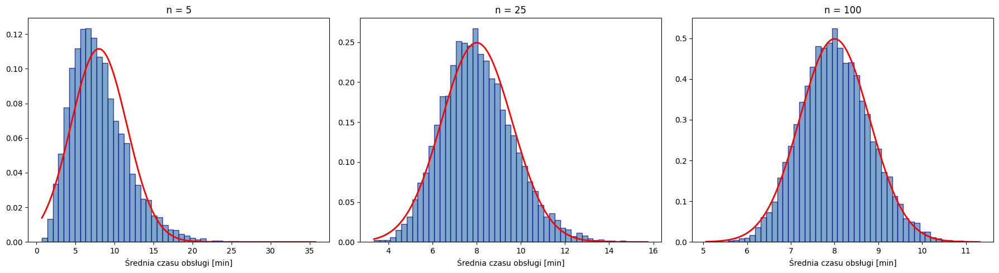

984

In [165]:
# Miejsce na rozwiązanie Zadania 3.1
N = 10_000
wielkosci = [5, 25, 100]
srednie_dict = {}
for n in wielkosci:
    srednie_dict[n] = [np.mean(np.random.exponential(scale=8, size=n)) for _ in range(N)]

# Zadanie 3.1b
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, n in zip(axes, wielkosci):
    ax.hist(srednie_dict[n], bins=50, density=True, alpha=0.7, color='steelblue', edgecolor='navy')
    x = np.linspace(min(srednie_dict[n]), max(srednie_dict[n]), 300)
    ax.plot(x, stats.norm.pdf(x, 8, 8/np.sqrt(n)), 'r-', linewidth=2)
    ax.set_title(f'n = {n}')
    ax.set_xlabel('Średnia czasu obsługi [min]')
plt.tight_layout()
plt.show()

# Zadanie 3.1c
sigma = 8
for n in wielkosci:
    SE = sigma / np.sqrt(n)

# Zadanie 3.1d
SE_25 = sigma / np.sqrt(25)
SE_100 = sigma / np.sqrt(100)
SE_25 / SE_100

# Zadanie 3.1e
n_wymagane = (1.96 * 8 / 0.5) ** 2
int(np.ceil(n_wymagane))


---
# Część 4: Przedziały ufności

Nigdy nie znamy **dokładnej** wartości parametru populacji (np. średniego wzrostu WSZYSTKICH Polaków). Mamy tylko **próbę** — mały wycinek.

**Przedział ufności** to zakres wartości, w którym z określonym prawdopodobieństwem (np. 95%) znajduje się **prawdziwa** wartość parametru.

Ogólna postać:

$$\text{przedział ufności} = \bar{x} \pm \text{margines błędu}$$

### Przedział ufności dla średniej (znane σ)

$$\bar{x} \pm z_{\alpha/2} \cdot \frac{\sigma}{\sqrt{n}}$$

### Przedział ufności dla średniej (nieznane σ — częstszy przypadek)

$$\bar{x} \pm t_{\alpha/2, n-1} \cdot \frac{s}{\sqrt{n}}$$

gdzie:
- $\bar{x}$ — średnia z próby
- $s$ — odchylenie standardowe z próby
- $n$ — wielkość próby
- $t_{\alpha/2, n-1}$ — wartość krytyczna z rozkładu t-Studenta
- $\alpha$ — poziom istotności (np. 0.05 dla 95% ufności)

### Typowe wartości $z_{\alpha/2}$

| Poziom ufności | α | z |
|---------------|---|---|
| 90% | 0.10 | 1.645 |
| 95% | 0.05 | 1.960 |
| 99% | 0.01 | 2.576 |

In [167]:
n = 50
proba = np.random.normal(loc=180, scale=7, size=n)
proba

array([180.8116512 , 170.81478703, 175.92215556, 182.47916214,
       192.39854818, 198.7078007 , 178.60457038, 181.34367483,
       168.03278887, 174.72988845, 177.85597195, 181.71699863,
       180.53463593, 177.53962674, 172.55961525, 175.56918633,
       171.33743711, 181.83828022, 182.773635  , 175.61741648,
       179.21946993, 186.60428914, 192.85379979, 182.56673816,
       182.12532558, 186.51071746, 176.86911949, 192.70770928,
       177.889332  , 178.88731259, 188.26791843, 165.67482223,
       184.55029817, 174.40171656, 182.19070424, 179.43752427,
       170.09868672, 183.99031946, 183.27282611, 182.01690874,
       175.73631803, 178.08651341, 182.26924757, 182.33671465,
       172.41159437, 181.1133962 , 180.56030873, 174.58143555,
       171.68454497, 175.58025028])

In [168]:
# Przykład 1: Mierzymy wzrost 50 losowych mężczyzn
# Prawdziwa średnia populacji: μ = 180 cm, σ = 7 cm (udajmy, że nie znamy μ)

n = 50
proba = np.random.normal(loc=180, scale=7, size=n)

# Statystyki z próby
srednia_proby = np.mean(proba)
odch_proby = np.std(proba, ddof=1)  # ddof=1 → odchylenie z próby

print(f"Próba: n = {n}")
print(f"Średnia z próby: {srednia_proby:.2f} cm")
print(f"Odch. std. z próby: {odch_proby:.2f} cm")

Próba: n = 50
Średnia z próby: 179.20 cm
Odch. std. z próby: 7.71 cm


In [170]:
# Przedział ufności 95% (używamy rozkładu t)
alfa = 0.05
t_krytyczne = stats.t.ppf(1 - alfa/2, df=n-1)
blad_standardowy = odch_proby / np.sqrt(n)
margines = t_krytyczne * blad_standardowy

dolna_granica = srednia_proby - margines
gorna_granica = srednia_proby + margines

print(f"Przedział ufności 95%")
print(f"t krytyczne (df={n-1}): {t_krytyczne:.4f}")
print(f"Błąd standardowy: {blad_standardowy:.4f}")
print(f"Margines błędu: ±{margines:.2f} cm")
print(f"\nPrzedział ufności: ({dolna_granica:.2f}, {gorna_granica:.2f}) cm")
print(f"\nInterpretacja: Z 95% pewnością średni wzrost mężczyzn w populacji mieści się między {dolna_granica:.2f} a {gorna_granica:.2f} cm")

Przedział ufności 95%
t krytyczne (df=49): 2.0096
Błąd standardowy: 1.0905
Margines błędu: ±2.19 cm

Przedział ufności: (177.01, 181.39) cm

Interpretacja: Z 95% pewnością średni wzrost mężczyzn w populacji mieści się między 177.01 a 181.39 cm


In [171]:
# Wbudowana funkcja scipy — krótsza droga do tego samego wyniku
przedzial = stats.t.interval(confidence=0.95, df=n-1, loc=srednia_proby, scale=blad_standardowy)
print(f"Wbudowana funkcja scipy: ({przedzial[0]:.2f}, {przedzial[1]:.2f})")

Wbudowana funkcja scipy: (177.01, 181.39)


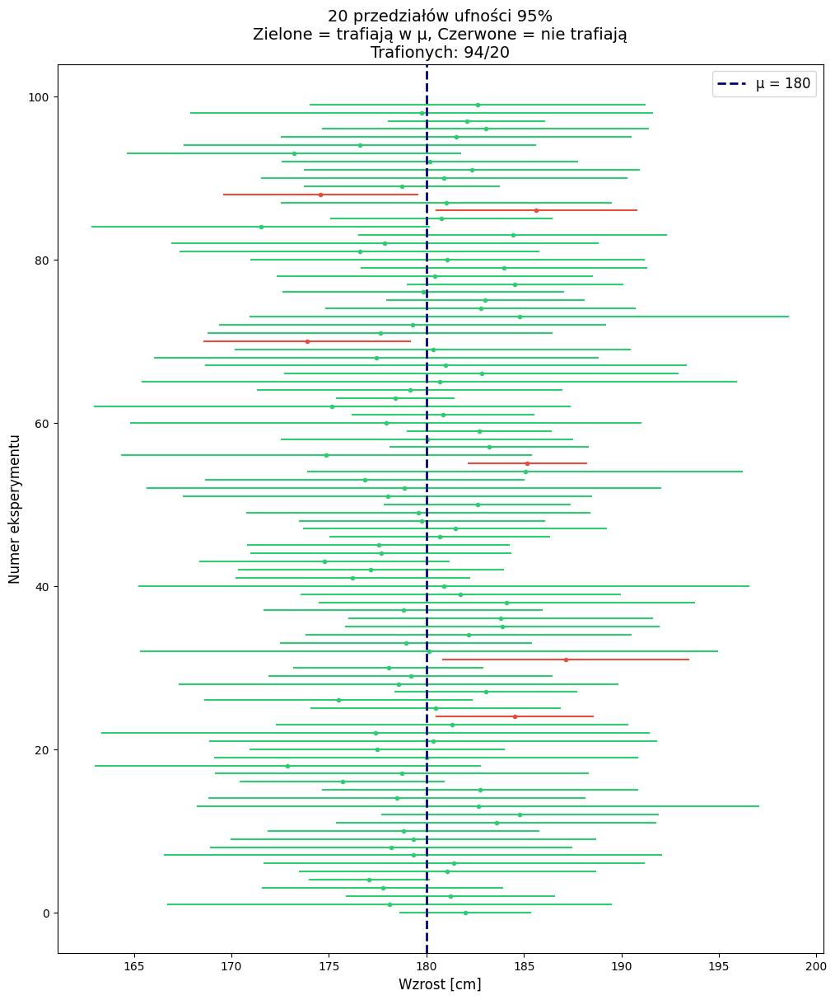

In [227]:
# Wizualizacja: co znaczy "95% ufności"?
# Powtórzmy eksperyment 100 razy — ile przedziałów pokryje prawdziwą średnią?
n = 5
mu_prawdziwe = 180
sigma = 7
n_eksperymentow = 100

fig, ax = plt.subplots(figsize=(12, 14))

trafienia = 0

for i in range(n_eksperymentow):
    proba_i = np.random.normal(mu_prawdziwe, sigma, n)
    srednia_i = np.mean(proba_i)
    se_i = np.std(proba_i, ddof=1) / np.sqrt(n)
    przedzial_i = stats.t.interval(0.95, df=n-1, loc=srednia_i, scale=se_i)
    
    # Czy przedział zawiera prawdziwą średnią?
    trafiony = przedzial_i[0] <= mu_prawdziwe <= przedzial_i[1]
    trafienia += trafiony
    
    kolor = '#2ecc71' if trafiony else '#e74c3c'
    ax.plot([przedzial_i[0], przedzial_i[1]], [i, i], color=kolor, linewidth=1.5)
    ax.plot(srednia_i, i, 'o', color=kolor, markersize=3)

ax.axvline(x=mu_prawdziwe, color='navy', linestyle='--', linewidth=2, label=f'μ = {mu_prawdziwe}')
ax.set_xlabel('Wzrost [cm]', fontsize=12)
ax.set_ylabel('Numer eksperymentu', fontsize=12)
ax.set_title(f'20 przedziałów ufności 95%\n'
             f'Zielone = trafiają w μ, Czerwone = nie trafiają\n'
             f'Trafionych: {trafienia}/20', fontsize=14)
ax.legend(fontsize=12)
plt.show()

In [180]:
# Jak wielkość próby wpływa na szerokość przedziału?
mu_prawdziwe = 180
sigma = 7

wielkosci_prob = [10, 25, 50, 100, 250, 500]

print(f"{'n':>5} | {'Średnia':>8} | {'Margines':>10} | {'Przedział 95%':>25}")
print("-" * 60)

for n in wielkosci_prob:
    proba = np.random.normal(mu_prawdziwe, sigma, n)
    m = np.mean(proba)
    se = np.std(proba, ddof=1) / np.sqrt(n)
    ci = stats.t.interval(0.95, df=n-1, loc=m, scale=se)
    margines = ci[1] - m
    print(f"{n:>5} | {m:>8.2f} | {margines:>10.2f} | ({ci[0]:>8.2f}, {ci[1]:>8.2f})")

print(f"\nWniosek: Większa próba → węższy (dokładniejszy) przedział ufności!")

    n |  Średnia |   Margines |             Przedział 95%
------------------------------------------------------------
   10 |   181.18 |       4.15 | (  177.03,   185.33)
   25 |   180.68 |       3.46 | (  177.23,   184.14)
   50 |   180.11 |       1.81 | (  178.30,   181.92)
  100 |   179.11 |       1.30 | (  177.80,   180.41)
  250 |   180.17 |       0.80 | (  179.37,   180.97)
  500 |   179.99 |       0.61 | (  179.37,   180.60)

Wniosek: Większa próba → węższy (dokładniejszy) przedział ufności!


### Podsumowanie przedziałów ufności

1. Przedział ufności **nie** oznacza, że prawdziwa średnia jest w nim z prawdopodobieństwem 95%. Oznacza, że gdybyśmy powtórzyli eksperyment wiele razy, ~95% takich przedziałów zawierałoby prawdziwą średnią.
2. **Szerszy** przedział = mniej precyzyjny, ale pewniejszy.
3. Szerokość przedziału zależy od:
   - **Poziomu ufności** (wyższy → szerszy)
   - **Wielkości próby** (większa → węższy)
   - **Zmienności danych** (większa → szerszy)

---
## Zadania do samodzielnego rozwiązania — Część 4

### Zadanie 4.1
Zmierzono czas dojazdu do pracy 30 losowych pracowników (w minutach): wygeneruj dane z rozkładu `np.random.normal(35, 8, size=30)`.
- a) Oblicz 95% przedział ufności dla średniego czasu dojazdu.
- b) Oblicz 90% i 99% przedziały ufności. Porównaj ich szerokość.

### Zadanie 4.2
Chcesz oszacować średnią pensję w mieście z marginesem błędu nie większym niż 200 zł (przy 95% ufności). Odchylenie standardowe pensji to ok. 1500 zł.

Ile osób musisz zbadać?

**Wskazówka:** Przekształć wzór na margines: $n = \left(\frac{z_{\alpha/2} \cdot \sigma}{200}\right)^2$

### Zadanie 4.3
Wygeneruj 200 wartości z rozkładu normalnego N(50, 10). Podziel na 4 równe podpróby po 50 obserwacji. Oblicz 95% przedział ufności dla każdej podpróby. Czy wszystkie zawierają prawdziwą średnią?

In [222]:
# Miejsce na rozwiązanie Zadania 4.1
# stats.norm.rvs(35, 8, 30)
x = np.random.normal(35, 8, size=30)
n = len(x)
srednia_proby = np.mean(x)
blad_standardowy = np.std(x) / np.sqrt(n)

przedzial = stats.t.interval(confidence=0.90, df=n-1, loc=srednia_proby, scale=blad_standardowy)
print(f"Przedział ufności 90%: ({przedzial[0]:.2f}, {przedzial[1]:.2f})")

przedzial = stats.t.interval(confidence=0.95, df=n-1, loc=srednia_proby, scale=blad_standardowy)
print(f"Przedział ufności 95%: ({przedzial[0]:.2f}, {przedzial[1]:.2f})")

przedzial = stats.t.interval(confidence=0.99, df=n-1, loc=srednia_proby, scale=blad_standardowy)
print(f"Przedział ufności 99%: ({przedzial[0]:.2f}, {przedzial[1]:.2f})")

Przedział ufności 90%: (33.19, 38.79)
Przedział ufności 95%: (32.62, 39.36)
Przedział ufności 99%: (31.45, 40.53)


In [229]:
print(stats.norm.ppf(0.025))
print(stats.norm.ppf(0.975))

-1.9599639845400545
1.959963984540054


In [230]:
# Miejsce na rozwiązanie Zadania 4.2
import math
z = 1.96 # stats.norm.ppf(0.975) # 95% ufności, ale obcinamy po 2.5% z obu stron, więc 0.975
sigma = 1500
E = 200
n = (z * sigma / E) ** 2
print("n =", n)
print("Minimalna liczba osób =", math.ceil(n))

n = 216.08999999999997
Minimalna liczba osób = 217


In [235]:
# Miejsce na rozwiązanie Zadania 4.3
dane = np.random.normal(50, 10, size=200)
podproby = [dane[i*50:(i+1)*50] for i in range(4)]
for p in podproby:
    sr = np.mean(p)
    se = np.std(p, ddof=1) / np.sqrt(len(p))
    ci = stats.t.interval(0.95, df=len(p)-1, loc=sr, scale=se)
    print(ci)

(np.float64(47.78597908418201), np.float64(53.44508030728576))
(np.float64(46.93558790934836), np.float64(53.271280272326536))
(np.float64(47.78596824331132), np.float64(53.74755182879921))
(np.float64(47.36427905395015), np.float64(52.43566936890458))


---
# Część 5: Testowanie hipotez statystycznych

**Testowanie hipotez** to procedura, w której na podstawie danych z próby decydujemy, czy pewne twierdzenie o populacji jest prawdziwe.

### Kroki procedury:

1. **Sformułuj hipotezy:**
   - $H_0$ (hipoteza zerowa) — "nic się nie zmieniło", "nie ma różnicy", status quo
   - $H_1$ (hipoteza alternatywna) — "jest różnica", "jest efekt"

2. **Wybierz poziom istotności** $\alpha$ (zwykle 0.05 = 5%)

3. **Oblicz statystykę testową** z danych

4. **Oblicz p-wartość** (p-value)

5. **Decyzja:**
   - Jeśli $p \leq \alpha$ → **odrzucamy** $H_0$ (wynik istotny statystycznie)
   - Jeśli $p > \alpha$ → **nie odrzucamy** $H_0$ (brak dowodów na odrzucenie)

### Czym jest p-wartość?

**p-wartość** to prawdopodobieństwo uzyskania wyników **tak ekstremalnych** (lub bardziej) jak te zaobserwowane, **zakładając że $H_0$ jest prawdziwa**.

Intuicja:
- Małe $p$ → dane są **bardzo mało prawdopodobne** przy $H_0$ → $H_0$ pewnie jest fałszywa
- Duże $p$ → dane są **spójne** z $H_0$ → nie mamy powodu jej odrzucić

### Rodzaje testów statystycznych
| Test | Kiedy stosujemy? | Przykład |
|------|-----------------|----------|
| **Test t — 1 próba** | Czy średnia = określona wartość? | Czy batony ważą 50g? |
| **Test t — 2 niezależne próby** | Czy dwie grupy się różnią? | Test A/B na stronie internetowej |
| **Test t — parowy** | Czy jest zmiana przed/po? | Wyniki przed i po kursie |
| **ANOVA** | Czy ≥3 grupy się różnią? | Porównanie 3 kampanii marketingowych |
| **Test chi-kwadrat** | Czy zmienne kategoryczne są niezależne? | Czy płeć wpływa na wybór produktu? |
| **Test Shapiro-Wilka** | Czy dane mają rozkład normalny? | Sprawdzenie założeń testu t |
| **Test Manna-Whitneya** | Porównanie 2 grup (dane nienormalne) | Alternatywa dla testu t |

Poniżej pokażemy **dwa częste zastosowania** w praktyce biznesowej: **test A/B** (test t dla dwóch prób) oraz **ANOVA** (porównanie wielu grup).

## 5.2. Test A/B — test t dla dwóch niezależnych prób

**Test A/B** to jedno z najważniejszych narzędzi w marketingu i projektowaniu produktów cyfrowych. Polega na podziale użytkowników na dwie grupy i sprawdzeniu, czy zmiana (np. nowy wygląd strony) wpływa na wyniki. [Przykład](https://www.google.com/search?q=test+a%2Fb+buy+now&sca_esv=6e72ffa629272dce&rlz=1C5CHFA_enPL1190PL1190&udm=2&biw=1920&bih=849&sxsrf=ANbL-n5xdAyLxwldywsqmGBbUmsXu4SnPg%3A1773470926708&ei=zgS1aYP6KunCwPAPrdLUsQ8&ved=0ahUKEwiDmeyE5p6TAxVpIRAIHS0pNfYQ4dUDCBI&uact=5&oq=test+a%2Fb+buy+now&gs_lp=Egtnd3Mtd2l6LWltZyIQdGVzdCBhL2IgYnV5IG5vd0itGlDyCViPGXABeACQAQCYAU6gAY0EqgEBOLgBA8gBAPgBAZgCBKACywHCAgUQABiABMICBBAAGB7CAgYQABgFGB7CAgYQABgIGB6YAwCIBgGSBwE0oAfKCLIHATO4B8cBwgcFMS4xLjLIBwiACAA&sclient=gws-wiz-img#sv=CAMSVhoyKhBlLWRjUERWbUNhT0p2dmxNMg5kY1BEVm1DYU9KdnZsTToOQW9yUkE4c2x6THJWRk0gBCocCgZtb3NhaWMSEGUtZGNQRFZtQ2FPSnZ2bE0YADABGAcg0IzxETACSggQAhgCIAIoAg)

- $H_0: \mu_A = \mu_B$ (obie wersje dają takie same wyniki)
- $H_1: \mu_A \neq \mu_B$ (jest istotna różnica)

### Przykład: Test A/B w sklepie internetowym

Sklep internetowy testuje dwa warianty strony głównej:
- **Wersja A** (kontrolna): obecny wygląd
- **Wersja B** (testowa): nowy przycisk "Kup teraz" i zmieniony układ

Mierzymy **czas spędzony na stronie** (w sekundach) dla 50 losowych użytkowników z każdej grupy.

In [236]:
# Test A/B: czas spędzony na stronie sklepu internetowego
np.random.seed(42)

# Wersja A (kontrolna): średnio 120 sekund na stronie
wersja_A = np.random.normal(loc=120, scale=30, size=50)

# Wersja B (nowy design): średnio 135 sekund na stronie
wersja_B = np.random.normal(loc=135, scale=28, size=50)

print("Statystyki opisowe:")
print(f"{'':>20} {'Wersja A (kontrolna)':>22} {'Wersja B (nowa)':>18}")
print(f"{'Średnia [s]':>20} {np.mean(wersja_A):>22.1f} {np.mean(wersja_B):>18.1f}")
print(f"{'Odch. std. [s]':>20} {np.std(wersja_A, ddof=1):>22.1f} {np.std(wersja_B, ddof=1):>18.1f}")
print(f"{'Liczba użytkowników':>20} {len(wersja_A):>22} {len(wersja_B):>18}")

Statystyki opisowe:
                       Wersja A (kontrolna)    Wersja B (nowa)
         Średnia [s]                  113.2              135.5
      Odch. std. [s]                   28.0               24.5
 Liczba użytkowników                     50                 50


/var/folders/hn/9mqk1gj552v3lhr3_t95txlw0000gn/T/ipykernel_1896/474798580.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot([wersja_A, wersja_B], labels=['Wersja A\n(kontrolna)', 'Wersja B\n(nowa)'],


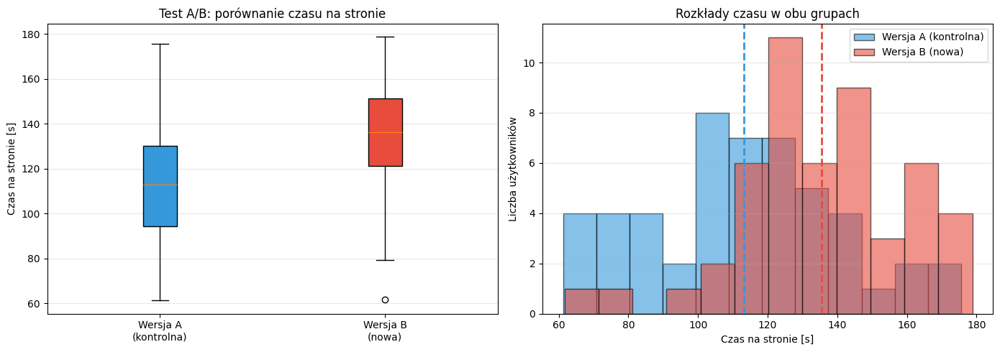

In [237]:
# Wizualizacja wyników testu A/B
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
bp = axes[0].boxplot([wersja_A, wersja_B], labels=['Wersja A\n(kontrolna)', 'Wersja B\n(nowa)'],
                     patch_artist=True)
bp['boxes'][0].set_facecolor('#3498db')
bp['boxes'][1].set_facecolor('#e74c3c')
axes[0].set_ylabel('Czas na stronie [s]')
axes[0].set_title('Test A/B: porównanie czasu na stronie')
axes[0].grid(axis='y', alpha=0.3)

# Histogramy
axes[1].hist(wersja_A, bins=12, alpha=0.6, color='#3498db', label='Wersja A (kontrolna)', edgecolor='black')
axes[1].hist(wersja_B, bins=12, alpha=0.6, color='#e74c3c', label='Wersja B (nowa)', edgecolor='black')
axes[1].axvline(np.mean(wersja_A), color='#3498db', linestyle='--', linewidth=2)
axes[1].axvline(np.mean(wersja_B), color='#e74c3c', linestyle='--', linewidth=2)
axes[1].set_xlabel('Czas na stronie [s]')
axes[1].set_ylabel('Liczba użytkowników')
axes[1].set_title('Rozkłady czasu w obu grupach')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [238]:
wersja_A

array([134.90142459, 115.85207096, 139.43065614, 165.69089569,
       112.97539876, 112.97589129, 167.37638447, 143.02304187,
       105.91576842, 136.27680131, 106.09746922, 106.02810739,
       127.25886815,  62.60159266,  68.25246502, 103.13137412,
        89.61506639, 129.42741998,  92.75927773,  77.63088896,
       163.96946307, 113.22671099, 122.02584614,  77.25755441,
       103.66851826, 123.32767769,  85.47019268, 131.27094055,
       101.9808393 , 111.24918751, 101.94880163, 175.56834554,
       119.59508326,  88.26867213, 144.67634736,  83.3746905 ,
       126.26590785,  61.20989628,  80.15441853, 125.90583708,
       142.1539974 , 125.14104844, 116.53055153, 110.96688913,
        75.64434029,  98.40467375, 106.18083687, 151.71366679,
       130.30854869,  67.10879534])

In [241]:
wersja_B

array([144.07435114, 124.21769615, 116.04618399, 152.12693609,
       163.86798663, 161.07584334, 111.50190935, 126.34205348,
       144.27537608, 162.31526356, 121.58312134, 129.80154865,
       104.02262073, 101.50621453, 157.75072303, 172.9747208 ,
       132.9837166 , 163.09892114, 145.1258087 , 116.93664687,
       145.11907695, 178.06502386, 133.9968709 , 178.81002236,
        61.64713709, 158.01327012, 137.43731791, 126.62779419,
       137.56930174,  79.34807039, 128.84918714, 144.999152  ,
       176.38103325, 120.48843389, 112.36217912, 120.95080278,
       160.6312593 , 144.20503107, 120.16671429, 149.37148813,
       137.71817138, 162.12205973, 115.34251337, 125.8254599 ,
       124.02097171,  94.02158145, 143.29136776, 142.30954762,
       135.14317679, 128.43156027])

In [242]:
# Test t dla dwóch niezależnych prób
t_stat, p_value = stats.ttest_ind(wersja_A, wersja_B)

alfa = 0.05

print(f"TEST A/B — TEST t DLA DWÓCH NIEZALEŻNYCH PRÓB")
print(f"H₀: μ_A = μ_B (obie wersje strony dają taki sam czas)")
print(f"H₁: μ_A ≠ μ_B (nowa wersja zmienia czas na stronie)")
print(f"α = {alfa}")
print(f"\nStatystyka t = {t_stat:.4f}")
print(f"p-wartość = {p_value:.6f}")
print(f"\nDecyzja: ", end='')
if p_value <= alfa:
    print(f"p = {p_value:.4f} ≤ {alfa} → ODRZUCAMY H₀")
    print(f"\nWniosek: Nowa wersja strony (B) ISTOTNIE zmienia czas spędzony na stronie.")
    roznica = np.mean(wersja_B) - np.mean(wersja_A)
    print(f"Średnia różnica: {roznica:.1f} sekund ({'więcej' if roznica > 0 else 'mniej'} na nowej stronie)")
else:
    print(f"p = {p_value:.4f} > {alfa} → NIE ODRZUCAMY H₀")
    print(f"\nWniosek: Brak istotnej statystycznie różnicy — obie wersje dają podobne wyniki.")

TEST A/B — TEST t DLA DWÓCH NIEZALEŻNYCH PRÓB
H₀: μ_A = μ_B (obie wersje strony dają taki sam czas)
H₁: μ_A ≠ μ_B (nowa wersja zmienia czas na stronie)
α = 0.05

Statystyka t = -4.2316
p-wartość = 0.000052

Decyzja: p = 0.0001 ≤ 0.05 → ODRZUCAMY H₀

Wniosek: Nowa wersja strony (B) ISTOTNIE zmienia czas spędzony na stronie.
Średnia różnica: 22.3 sekund (więcej na nowej stronie)


## 5.3. ANOVA — porównanie wielu grup naraz

Co jeśli mamy **więcej niż dwie grupy**? Nie możemy po prostu zrobić wielu testów t (to zwiększa ryzyko błędu I rodzaju!). Zamiast tego używamy **ANOVA** (*Analysis of Variance*).

- $H_0$: wszystkie grupy mają tę samą średnią ($\mu_1 = \mu_2 = ... = \mu_k$)
- $H_1$: co najmniej jedna grupa różni się od pozostałych

### Przykład: Porównanie trzech kampanii e-mailowych

Firma marketingowa testuje **3 warianty kampanii e-mailowej** i mierzy **współczynnik klikalności (CTR)** w procentach dla próby klientów z każdej grupy.

In [243]:
# ANOVA: porównanie 3 kampanii e-mailowych (CTR w %)
np.random.seed(42)

kampania_A = np.random.normal(loc=2.5, scale=0.8, size=40)   # standardowa
kampania_B = np.random.normal(loc=3.2, scale=0.9, size=40)   # z personalizacją
kampania_C = np.random.normal(loc=2.7, scale=0.7, size=40)   # z rabatem

print("Statystyki opisowe — CTR (%) w każdej kampanii:")
print(f"{'Kampania':<20} {'Średnia':>10} {'Odch. std.':>12} {'n':>5}")
print("-" * 50)
for nazwa, dane in [('A (standardowa)', kampania_A), 
                     ('B (personalizacja)', kampania_B), 
                     ('C (z rabatem)', kampania_C)]:
    print(f"{nazwa:<20} {np.mean(dane):>10.2f}% {np.std(dane, ddof=1):>11.2f}% {len(dane):>5}")

Statystyki opisowe — CTR (%) w każdej kampanii:
Kampania                Średnia   Odch. std.     n
--------------------------------------------------
A (standardowa)            2.33%        0.76%    40
B (personalizacja)         3.17%        0.87%    40
C (z rabatem)              2.71%        0.60%    40


/var/folders/hn/9mqk1gj552v3lhr3_t95txlw0000gn/T/ipykernel_1896/2062028608.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot([kampania_A, kampania_B, kampania_C],


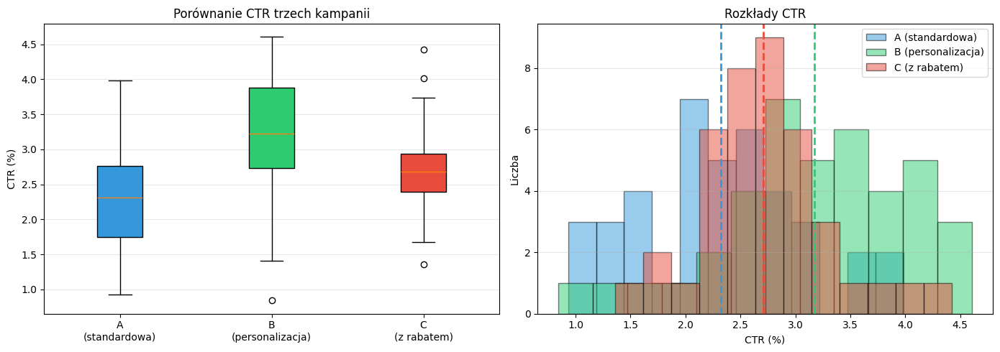

In [244]:
# Wizualizacja: boxplot 3 kampanii
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bp = axes[0].boxplot([kampania_A, kampania_B, kampania_C], 
                     labels=['A\n(standardowa)', 'B\n(personalizacja)', 'C\n(z rabatem)'],
                     patch_artist=True)
kolory_box = ['#3498db', '#2ecc71', '#e74c3c']
for box, kolor in zip(bp['boxes'], kolory_box):
    box.set_facecolor(kolor)
axes[0].set_ylabel('CTR (%)')
axes[0].set_title('Porównanie CTR trzech kampanii')
axes[0].grid(axis='y', alpha=0.3)

# Histogramy nałożone
for dane, nazwa, kolor in zip([kampania_A, kampania_B, kampania_C],
                               ['A (standardowa)', 'B (personalizacja)', 'C (z rabatem)'],
                               kolory_box):
    axes[1].hist(dane, bins=12, alpha=0.5, color=kolor, label=nazwa, edgecolor='black')
    axes[1].axvline(np.mean(dane), color=kolor, linestyle='--', linewidth=2)
axes[1].set_xlabel('CTR (%)')
axes[1].set_ylabel('Liczba')
axes[1].set_title('Rozkłady CTR')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [245]:
kampania_A

array([2.89737132, 2.38938856, 3.01815083, 3.71842389, 2.3126773 ,
       2.31269043, 3.76337025, 3.11394778, 2.12442049, 2.93404803,
       2.12926585, 2.1274162 , 2.69356982, 0.9693758 , 1.12006573,
       2.05016998, 1.6897351 , 2.75139787, 1.77358074, 1.37015704,
       3.67251902, 2.31937896, 2.55402256, 1.36020145, 2.06449382,
       2.58873807, 1.57920514, 2.80055841, 2.01948905, 2.266645  ,
       2.01863471, 3.98182255, 2.48920222, 1.65383126, 3.15803593,
       1.52332508, 2.66709088, 0.9322639 , 1.43745116, 2.65748899])

In [246]:
# ANOVA — jednoczynnikowa analiza wariancji
F_stat, p_value = stats.f_oneway(kampania_A, kampania_B, kampania_C)

alfa = 0.05

print(f"ANOVA — PORÓWNANIE 3 KAMPANII")
print(f"H₀: μ_A = μ_B = μ_C (wszystkie kampanie dają taki sam CTR)")
print(f"H₁: co najmniej jedna kampania ma inny średni CTR")
print(f"α = {alfa}")
print(f"\nStatystyka F = {F_stat:.4f}")
print(f"p-wartość = {p_value:.6f}")
print(f"\nDecyzja: ", end='')
if p_value <= alfa:
    print(f"p = {p_value:.4f} ≤ {alfa} → ODRZUCAMY H₀")
    print(f"\nWniosek: Co najmniej jedna kampania daje ISTOTNIE RÓŻNY wynik CTR.")
    print(f"Kampania B (personalizacja) ma najwyższy średni CTR = {np.mean(kampania_B):.2f}%")
    print(f"\nUwaga: ANOVA mówi, że JEST różnica, ale nie mówi MIĘDZY KTÓRYMI grupami.")
    print(f"Do tego potrzebne są testy post-hoc (np. Tukey HSD).")
else:
    print(f"p = {p_value:.4f} > {alfa} → NIE ODRZUCAMY H₀")
    print(f"\nWniosek: Brak istotnych statystycznie różnic między kampaniami.")

ANOVA — PORÓWNANIE 3 KAMPANII
H₀: μ_A = μ_B = μ_C (wszystkie kampanie dają taki sam CTR)
H₁: co najmniej jedna kampania ma inny średni CTR
α = 0.05

Statystyka F = 12.7619
p-wartość = 0.000010

Decyzja: p = 0.0000 ≤ 0.05 → ODRZUCAMY H₀

Wniosek: Co najmniej jedna kampania daje ISTOTNIE RÓŻNY wynik CTR.
Kampania B (personalizacja) ma najwyższy średni CTR = 3.17%

Uwaga: ANOVA mówi, że JEST różnica, ale nie mówi MIĘDZY KTÓRYMI grupami.
Do tego potrzebne są testy post-hoc (np. Tukey HSD).


In [248]:
print(stats.tukey_hsd(kampania_A, kampania_B, kampania_C))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.849     0.000    -1.248    -0.449
 (0 - 2)     -0.382     0.064    -0.782     0.017
 (1 - 0)      0.849     0.000     0.449     1.248
 (1 - 2)      0.467     0.018     0.067     0.866
 (2 - 0)      0.382     0.064    -0.017     0.782
 (2 - 1)     -0.467     0.018    -0.866    -0.067



## 5.5. Błędy w testowaniu hipotez

| | $H_0$ jest prawdziwa | $H_0$ jest fałszywa |
|---|---|---|
| **Odrzucamy $H_0$** | ❌ Błąd I rodzaju (α) | ✅ Poprawna decyzja |
| **Nie odrzucamy $H_0$** | ✅ Poprawna decyzja | ❌ Błąd II rodzaju (β) |

- **Błąd I rodzaju (α)** — fałszywy alarm: mówimy, że jest efekt, choć go nie ma
- **Błąd II rodzaju (β)** — przeoczenie: nie zauważamy prawdziwego efektu

**Analogia z sądem:**
- $H_0$: oskarżony jest niewinny
- Błąd I rodzaju: skazanie niewinnego (fałszywy alarm)
- Błąd II rodzaju: uniewinnienie winnego (przeoczenie)

Inna analogia: https://economics.stackexchange.com/questions/27677/type-i-error-type-ii-error-pregnancy-test-analogy-is-it-legit

## 5.5. Praktyczne wskazówki

### Kiedy używać jakiego testu?

| Sytuacja | Test | Funkcja w `scipy` |
|----------|------|-------------------|
| Porównanie średniej z wartością | Test t (1 próba) | `stats.ttest_1samp()` |
| Porównanie 2 niezależnych grup (test A/B) | Test t (2 próby) | `stats.ttest_ind()` |
| Porównanie przed/po (te same osoby) | Test t (parowy) | `stats.ttest_rel()` |
| Porównanie ≥3 grup | ANOVA | `stats.f_oneway()` |
| Sprawdzenie normalności | Test Shapiro-Wilka | `stats.shapiro()` |

### Częste błędy i mity

1. **p < 0.05 ≠ "udowodnione"** → mówi tylko o sile dowodów, nie o pewności
2. **p > 0.05 ≠ "brak efektu"** → brak dowodów ≠ dowód braku
3. **Istotność statystyczna ≠ istotność praktyczna** → mała różnica może być statystycznie istotna przy dużej próbie
4. **Nie rób wielu testów na tych samych danych** → zwiększa ryzyko błędu I rodzaju (dlatego mamy ANOVA!)

---
## Zadania do samodzielnego rozwiązania — Część 5

### Zadanie 5.1 (Test A/B)
Sklep internetowy testuje dwie wersje strony produktu:
- Wersja A: `np.random.normal(loc=45, scale=12, size=60)` — średnia wartość zamówienia [zł]
- Wersja B (nowy design): `np.random.normal(loc=52, scale=15, size=55)` — średnia wartość zamówienia [zł]

Wykonaj pełną analizę testu A/B:
1. Oblicz statystyki opisowe obu grup
2. Narysuj boxplot i histogramy
3. Sprawdź normalność danych (test Shapiro-Wilka) https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html
4. Wykonaj test t dla dwóch niezależnych prób
5. Napisz wniosek: czy nowy design istotnie zwiększa wartość zamówienia?

### Zadanie 5.2 (ANOVA)
Firma porównuje efektywność **4 kanałów reklamowych** mierzoną liczbą nowych klientów dziennie:
- Facebook: `np.random.normal(loc=22, scale=5, size=30)`
- Google Ads: `np.random.normal(loc=28, scale=6, size=30)`
- Instagram: `np.random.normal(loc=25, scale=4, size=30)`
- TikTok: `np.random.normal(loc=30, scale=7, size=30)`

1. Narysuj boxploty i porównaj grupy wizualnie
2. Wykonaj test ANOVA (`stats.f_oneway`)
3. Zinterpretuj wynik — czy kanały różnią się istotnie?
4. Wykonaj test post-hoc https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html

/var/folders/hn/9mqk1gj552v3lhr3_t95txlw0000gn/T/ipykernel_1896/3899938614.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([wersja_A, wersja_B], labels=['Wersja A', 'Wersja B'])


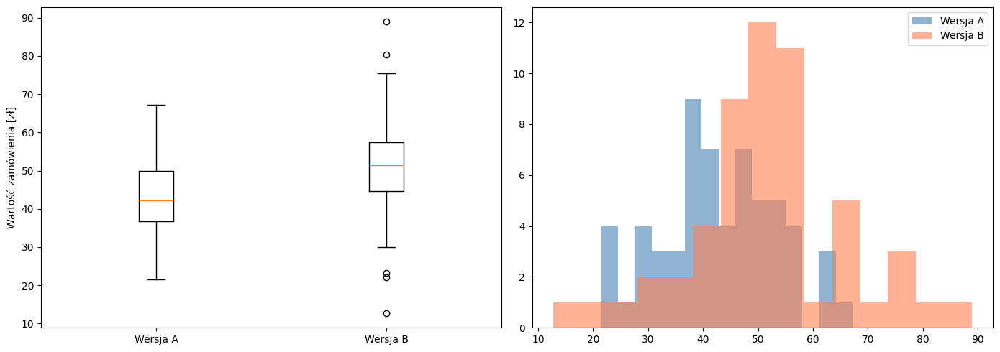

TtestResult(statistic=np.float64(-3.6110413196333795), pvalue=np.float64(0.00045622894743008744), df=np.float64(113.0))

In [249]:
# Miejsce na rozwiązanie Zadania 5.1 (Test A/B)
np.random.seed(42)
wersja_A = np.random.normal(loc=45, scale=12, size=60)
wersja_B = np.random.normal(loc=52, scale=15, size=55)

np.mean(wersja_A), np.std(wersja_A, ddof=1)
np.mean(wersja_B), np.std(wersja_B, ddof=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([wersja_A, wersja_B], labels=['Wersja A', 'Wersja B'])
axes[0].set_ylabel('Wartość zamówienia [zł]')
axes[1].hist(wersja_A, bins=15, alpha=0.6, label='Wersja A', color='steelblue')
axes[1].hist(wersja_B, bins=15, alpha=0.6, label='Wersja B', color='coral')
axes[1].legend()
plt.tight_layout()
plt.show()

stats.shapiro(wersja_A)
stats.shapiro(wersja_B)

stats.ttest_ind(wersja_A, wersja_B)

/var/folders/hn/9mqk1gj552v3lhr3_t95txlw0000gn/T/ipykernel_1896/162339866.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([facebook, google, instagram, tiktok],


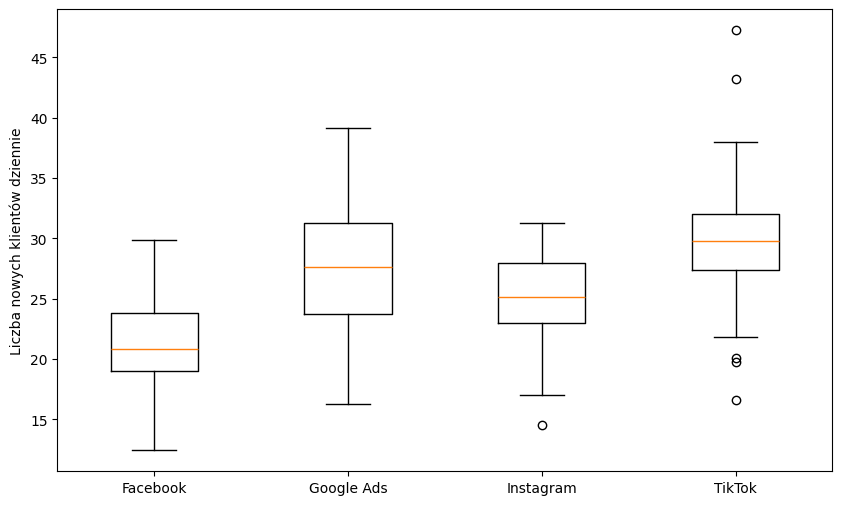

In [250]:
# Miejsce na rozwiązanie Zadania 5.2 (ANOVA)
np.random.seed(42)
facebook = np.random.normal(loc=22, scale=5, size=30)
google = np.random.normal(loc=28, scale=6, size=30)
instagram = np.random.normal(loc=25, scale=4, size=30)
tiktok = np.random.normal(loc=30, scale=7, size=30)

plt.figure(figsize=(10, 6))
plt.boxplot([facebook, google, instagram, tiktok],
            labels=['Facebook', 'Google Ads', 'Instagram', 'TikTok'])
plt.ylabel('Liczba nowych klientów dziennie')
plt.show()

stats.f_oneway(facebook, google, instagram, tiktok)

stats.tukey_hsd(facebook, google, instagram, tiktok)